# Задание № 3. Прикладные дифференциальные уравнения


In [1]:
%pip install numpy scipy matplotlib ipython

mambajs 0.21.4

Process pip requirements ...

Requirement numpy already handled by conda/micromamba/mamba.
Requirement scipy already handled by conda/micromamba/mamba.
Requirement matplotlib already handled by conda/micromamba/mamba.
Requirement ipython already handled by conda/micromamba/mamba.


In [2]:
from pathlib import Path
import io
import re

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.widgets import Button, Slider
from scipy.integrate import solve_ivp, quad
from scipy.optimize import root_scalar
from scipy.special import ellipk, ellipj
from IPython.display import HTML, Image, display

G = 9.81                      # ускорение свободного падения, м/с²
ANIM_FPS = 20                 # частота показа кадров; физическое время подписано
ANIM_FRAMES = 100
OUT = Path('results')
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'figure.dpi': 100,
    'savefig.dpi': 'figure',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'animation.embed_limit': 100,
    'animation.html': 'jshtml',
})

SAVED_FIGURES = []
SAVED_ANIMATIONS = []


def save_figure(fig, stem):
    """Сохранить PNG и встроить его в вывод ячейки."""
    path = OUT / f'{stem}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight', facecolor='white')
    SAVED_FIGURES.append(path)
    display(Image(filename=str(path)))
    plt.close(fig)
    print(f'Сохранен рисунок: {path}')


def display_animation(anim):
    """Плеер FuncAnimation с автономными кадрами и кнопками без внешних CSS."""
    html = anim.to_jshtml(fps=ANIM_FPS, embed_frames=True, default_mode='once')
    # Стандартные значки заменены текстом: плеер работает и без доступа к CDN.
    html = re.sub(r'<link\b[^>]*>', '', html)
    html = html.replace('<i class="fa fa-play fa-flip-horizontal"></i>', '◀')
    icons = {
        'fa-fast-backward': '|◀', 'fa-backward': '◀',
        'fa-play': '▶', 'fa-pause': 'Ⅱ', 'fa-forward': '▶',
        'fa-fast-forward': '▶|', 'fa-minus': '−', 'fa-plus': '+',
        'fa-step-backward': '◀|', 'fa-step-forward': '|▶',
    }
    for icon, symbol in icons.items():
        html = html.replace(f'<i class="fa {icon}"></i>', symbol)
    path = OUT / f'animation_{len(SAVED_ANIMATIONS) + 1:02d}.html'
    path.write_text('<!doctype html><meta charset="utf-8">' + html, encoding='utf-8')
    SAVED_ANIMATIONS.append(path)
    plt.close(anim._fig)
    display(HTML(html))
    print(f'Сохранен автономный плеер: {path}')


print(f'NumPy {np.__version__}; Matplotlib {matplotlib.__version__}')
print('Все величины в системе СИ, углы в формулах — в радианах.')

NumPy 2.5.4; Matplotlib 3.11.2
Все величины в системе СИ, углы в формулах — в радианах.


## 3.1. Задача о равномерном спуске

### 3.1.1. Постановка и исключение реакции

Выберем ось $x$ горизонтально, ось $y$ вертикально вверх. Точка массы $m$
движется без трения по неподвижной гладкой направляющей $y=f(x)$.
Требование задачи означает постоянную **вертикальную составляющую** скорости:

$$\dot y=-c,\qquad c>0,\qquad \ddot y=0.$$

Полная скорость при этом не обязана быть постоянной. Обозначим нормальную
реакцию направляющей через $\mathbf N=(N_x,N_y)$. Второй закон Ньютона:

$$m\ddot x=N_x,\qquad m\ddot y=N_y-mg.$$

Касательный вектор направляющей равен $(1,y')$, поэтому
$N_x+y'N_y=0$. Из $\ddot y=0$ получаем $N_y=mg$ и

$$\boxed{\ddot x=-g y'.}$$

Дважды продифференцируем геометрическую связь по времени:

$$\dot y=y'\dot x=-c,\qquad
0=\ddot y=y''\dot x^2+y'\ddot x.$$

Подставив $\dot x=-c/y'$ и $\ddot x=-g y'$, исключаем реакцию и время:

$$\frac{c^2 y''}{(y')^2}-g(y')^2=0,
\qquad\boxed{c^2y''=g(y')^4.}$$

### 3.1.2. Интегрирование и явный вид кривой

Рассмотрим движение вправо: $x(0)=x_0$, $y(0)=y_0$,
$\dot x(0)=u_0>0$, $\dot y(0)=-c$. Тогда $y'(x_0)=-c/u_0$.
При $p=y'$ уравнение разделяется:

$$\frac{dp}{p^4}=\frac{g}{c^2}\,dx,
\qquad -\frac1{3p^3}=\frac{g}{c^2}x+C_1.$$

Учитывая начальный наклон, имеем

$$y'(x)=-\frac{c}{\left[u_0^3+3gc(x-x_0)\right]^{1/3}}.$$

Повторное интегрирование дает

$$\boxed{
y(x)=y_0+\frac{u_0^2}{2g}
-\frac{\left[u_0^3+3gc(x-x_0)\right]^{2/3}}{2g}.
}$$

Для рассматриваемого движения $x\ge x_0$; регулярная ветвь формулы определена
при $u_0^3+3gc(x-x_0)>0$. Введем

$$x_v=x_0-\frac{u_0^3}{3gc},\qquad y_v=y_0+\frac{u_0^2}{2g}.$$

Тогда

$$\boxed{(x-x_v)^2=\frac{8g}{9c^2}(y_v-y)^3.}$$

Искомая кривая — ветвь **полукубической параболы**. Движение влево получается
отражением по горизонтали. Точка $(x_v,y_v)$ является особой точкой кривой;
начальные условия $u_0>0$ позволяют ее избежать. Начало движения из полного
покоя несовместимо с условием $\dot y=-c\ne0$.

### 3.1.3. Закон движения и физическая проверка

Из $\ddot x=gc/\dot x$ следует

$$\frac{d}{dt}\frac{\dot x^2}{2}=gc,
\qquad \dot x(t)=\sqrt{u_0^2+2gct}.$$

Следовательно,

$$\boxed{
x(t)=x_0+\frac{(u_0^2+2gct)^{3/2}-u_0^3}{3gc},
\qquad y(t)=y_0-ct.
}$$

Энергия сохраняется:

$$E=\frac m2(\dot x^2+c^2)+mgy
=\frac m2(u_0^2+c^2)+mgy_0.$$

Реакция $\mathbf N=m(gc/\dot x,g)$ перпендикулярна скорости, поэтому не
совершает работы: $\mathbf N\cdot\mathbf v=0$. Возрастающую кинетическую
энергию обеспечивает уменьшение потенциальной энергии.

In [3]:
def descent_motion(t, c=1.0, u0=2.0, x0=0.0, y0=3.0):
    """Точное движение с постоянной вертикальной скоростью -c."""
    if c <= 0 or u0 <= 0:
        raise ValueError('Нужны c > 0 и u0 > 0 для регулярной правой ветви.')
    t = np.asarray(t)
    vx = np.sqrt(u0**2 + 2 * G * c * t)
    x = x0 + (vx**3 - u0**3) / (3 * G * c)
    y = y0 - c * t
    return x, y, vx, np.full_like(t, -c, dtype=float)


def descent_curve(x, c=1.0, u0=2.0, x0=0.0, y0=3.0):
    base = u0**3 + 3 * G * c * (np.asarray(x) - x0)
    if np.any(base <= 0):
        raise ValueError('Точки должны лежать на регулярной правой ветви.')
    return y0 + u0**2 / (2 * G) - base**(2 / 3) / (2 * G)


descent_t = np.linspace(0, 3, 500)
descent_x, descent_y, descent_vx, descent_vy = descent_motion(descent_t)
descent_energy = 0.5 * (descent_vx**2 + descent_vy**2) + G * descent_y
assert np.allclose(descent_y, descent_curve(descent_x), atol=1e-12)
assert np.allclose(descent_energy, descent_energy[0], atol=1e-12)
assert np.allclose(descent_vy, -1.0)
# Проверка ОДУ по аналитическим производным.
descent_p = -1.0 / descent_vx
descent_pp = G / descent_vx**4
assert np.allclose(descent_pp, G * descent_p**4)
print('Проверены явная кривая, ОДУ, постоянство v_y и сохранение энергии.')
print(f'Удельная энергия E/m = {descent_energy[0]:.4f} Дж/кг')

Проверены явная кривая, ОДУ, постоянство v_y и сохранение энергии.
Удельная энергия E/m = 31.9300 Дж/кг


### 3.1.4. Статические графики

На левом графике меняются начальная горизонтальная скорость $u_0$ и постоянная
вертикальная скорость $-c$. Для каждой кривой показан спуск с $y_0=3$ м до
$y=0$. Справа показаны составляющие скорости при $c=1$ м/с, $u_0=2$ м/с.

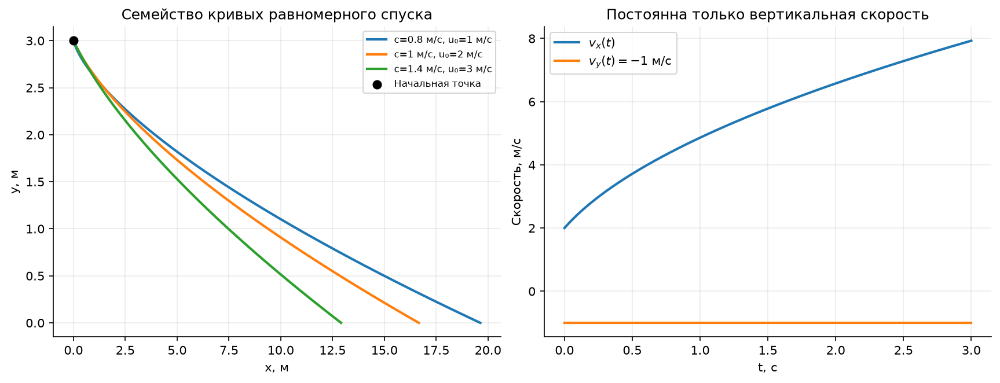

Сохранен рисунок: results/31_uniform_descent.png


In [4]:
descent_fig, descent_ax = plt.subplots(1, 2, figsize=(11.4, 4.3), constrained_layout=True)
for descent_c, descent_u0 in [(0.8, 1.0), (1.0, 2.0), (1.4, 3.0)]:
    descent_grid = np.linspace(0, 3 / descent_c, 400)
    descent_data = descent_motion(descent_grid, c=descent_c, u0=descent_u0)
    descent_ax[0].plot(descent_data[0], descent_data[1], lw=2,
                       label=f'c={descent_c:g} м/с, u₀={descent_u0:g} м/с')
descent_ax[0].scatter([0], [3], c='black', s=45, zorder=5, label='Начальная точка')
descent_ax[0].set(xlabel='x, м', ylabel='y, м', title='Семейство кривых равномерного спуска')
descent_ax[0].legend(fontsize=8)
descent_ax[1].plot(descent_t, descent_vx, lw=2, label=r'$v_x(t)$')
descent_ax[1].plot(descent_t, descent_vy, lw=2, label=r'$v_y(t)=-1$ м/с')
descent_ax[1].set(xlabel='t, с', ylabel='Скорость, м/с', title='Постоянна только вертикальная скорость')
descent_ax[1].legend()
save_figure(descent_fig, '31_uniform_descent')

### 3.1.5. Анимация

Кадры вычисляются по точным формулам при равномерной сетке **физического**
времени. Справа прямая $y(t)=y_0-ct$ наглядно показывает постоянство $v_y$.
Скорость воспроизведения можно менять кнопками плеера; подпись $t$ остается
временем моделируемого движения.

In [6]:
descent_anim_t = np.linspace(0, 3, ANIM_FRAMES)
descent_anim_x, descent_anim_y, descent_anim_vx, _ = descent_motion(descent_anim_t)
descent_anim_fig, descent_anim_ax = plt.subplots(
    1, 2, figsize=(11.0, 4.2), dpi=78, constrained_layout=True)
descent_anim_ax[0].plot(descent_x, descent_y, color='#2171b5', lw=2, label='Направляющая')
descent_anim_ax[0].plot(0, 3, 'o', color='gray', ms=5, label='Начало')
descent_dot, = descent_anim_ax[0].plot([], [], 'o', color='#d95f02', ms=10, label='Точка')
descent_trace, = descent_anim_ax[0].plot([], [], color='#d95f02', lw=2)
descent_anim_ax[0].set(xlim=(-0.8, descent_x[-1] + 0.8), ylim=(-0.25, 3.8),
                        xlabel='x, м', ylabel='y, м', title='Равномерный спуск по вертикали')
descent_anim_ax[0].legend(loc='lower left', fontsize=8)
descent_info = descent_anim_ax[0].text(0.03, 0.96, '', transform=descent_anim_ax[0].transAxes,
                                     va='top', fontsize=9, bbox=dict(facecolor='white', alpha=0.85))
descent_anim_ax[1].plot(descent_t, descent_y, color='#2171b5', lw=1.8, label=r'$y_0-ct$')
descent_time_dot, = descent_anim_ax[1].plot([], [], 'o', color='#d95f02', ms=9)
descent_anim_ax[1].set(xlim=(0, 3.05), ylim=(-0.2, 3.3), xlabel='t, с', ylabel='y, м',
                      title='Высота линейно убывает со временем')
descent_anim_ax[1].legend()


def descent_update(frame):
    descent_dot.set_data([descent_anim_x[frame]], [descent_anim_y[frame]])
    descent_trace.set_data(descent_anim_x[:frame + 1], descent_anim_y[:frame + 1])
    descent_time_dot.set_data([descent_anim_t[frame]], [descent_anim_y[frame]])
    descent_info.set_text(f't = {descent_anim_t[frame]:.2f} с\n'
                          f'vₓ = {descent_anim_vx[frame]:.2f} м/с; vᵧ = −1.00 м/с')
    return descent_dot, descent_trace, descent_time_dot, descent_info


descent_animation = FuncAnimation(descent_anim_fig, descent_update,
                                  frames=ANIM_FRAMES, interval=1000 / ANIM_FPS, blit=False)
display_animation(descent_animation)

Сохранен автономный плеер: results/animation_02.html


### Дополнительно: управление через `matplotlib.widgets`

Основной HTML-плеер выше работает в обычном Jupyter. Следующая функция
демонстрирует также `Slider` и `Button` из перечисленного в задании модуля
`matplotlib.widgets`: ползунок задает время, кнопка возвращает точку в начало.
Для живого взаимодействия с такими виджетами нужен интерактивный backend.

При желании установите `ipympl`, затем в **отдельной ячейке** выполните:

```python
%matplotlib widget
descent_controls = open_descent_controls()
```

Эта дополнительная ячейка не нужна для запуска пяти основных анимаций.

In [7]:
def open_descent_controls():
    """Интерактивный ползунок и кнопка; запускать с backend %matplotlib widget."""
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    fig.subplots_adjust(bottom=0.28)
    ax.plot(descent_x, descent_y, lw=2)
    dot, = ax.plot([0], [3], 'o', ms=9, color='#d95f02')
    ax.set(xlabel='x, м', ylabel='y, м', title='Выберите момент времени')
    slider_ax = fig.add_axes([0.18, 0.12, 0.58, 0.04])
    button_ax = fig.add_axes([0.80, 0.10, 0.14, 0.08])
    time_slider = Slider(slider_ax, 't, с', 0.0, 3.0, valinit=0.0)
    reset_button = Button(button_ax, 'В начало')

    def redraw(value):
        x, y, _, _ = descent_motion(float(value))
        dot.set_data([float(x)], [float(y)])
        fig.canvas.draw_idle()

    time_slider.on_changed(redraw)
    reset_button.on_clicked(lambda event: time_slider.reset())
    # Ссылки на виджеты должны сохраняться, иначе события могут перестать работать.
    fig._controls = (time_slider, reset_button)
    plt.show()
    return fig, time_slider, reset_button

## 3.2. Бильярд в прямоугольнике

**Условие.** Точка массы $m$ свободно движется в прямоугольнике
$0\leq x\leq a$, $0\leq y\leq b$ и упруго отражается от его сторон.
Нужно описать движение, классифицировать траектории и показать развертку и движение на торе.
Далее шар считается материальной точкой; вращение шара и трение отсутствуют.

### 3.2.1. Уравнения движения и отражение

Между ударами сила равна нулю:

$$m\ddot x=0,\qquad m\ddot y=0,\qquad
x(0)=x_0,\quad y(0)=y_0,\quad
\dot x(0)=v_{x0},\quad\dot y(0)=v_{y0}.$$

На гладкой стороне с единичной внешней нормалью $\boldsymbol n$ закон отражения имеет вид

$$\boxed{\boldsymbol v^+=\boldsymbol v^-
-2(\boldsymbol v^-\!\cdot\!\boldsymbol n)\boldsymbol n.}$$

Нормальная составляющая меняет знак, касательная сохраняется. Поэтому

$$\begin{array}{ll}
x=0\text{ или }x=a:&(v_x,v_y)\mapsto(-v_x,v_y),\\
y=0\text{ или }y=b:&(v_x,v_y)\mapsto(v_x,-v_y).
\end{array}$$

Скорость по модулю и энергия сохраняются:
$v^2=v_{x0}^2+v_{y0}^2$, $E=mv^2/2$.
В углу нет единственной нормали: классическая бильярдная траектория при точном попадании
в вершину не определена. Ниже выбраны траектории без таких попаданий;
это проверяется на всем изображаемом временном интервале.

### 3.2.2. Метод развертки и точная формула

При каждом ударе отражаем не скорость точки, а прямоугольник относительно соответствующей
стороны. В плоскости зеркальных копий точка движется по одной прямой:

$$X(t)=x_0+v_{x0}t,\qquad Y(t)=y_0+v_{y0}t.$$

Для возвращения в исходный прямоугольник введем треугольную волну

$$F_L(z)=L-\left|\bigl(z\bmod 2L\bigr)-L\right|,\qquad
0\leq z\bmod 2L<2L.$$

Тогда точное решение, включая все отражения от сторон, равно

$$\boxed{x(t)=F_a(x_0+v_{x0}t),\qquad
y(t)=F_b(y_0+v_{y0}t).}$$

На промежутках между ударами производная $F_L$ равна $+1$ или $-1$,
так что формула автоматически воспроизводит закон упругого отражения.
Численно интегрировать уравнение движения и исправлять выход точки за границу не нужно.

Две развернутые координаты можно рассматривать по модулю $2a$ и $2b$:

$$U=X\bmod 2a,\qquad V=Y\bmod 2b.$$

После склейки противоположных сторон прямоугольника $[0,2a)\times[0,2b)$
получаем плоский тор. На нем движение линейно и непрерывно при прохождении склеенных сторон.
Координаты бильярда получаются его складыванием; информация о направлении скорости
содержится в выборе одной из четырех зеркальных копий.

### 3.2.3. Периодические и иррациональные направления

Для возвращения **и координат, и скорости** нужны целые числа $q,p$ и время $T>0$, такие что

$$v_{x0}T=2aq,\qquad v_{y0}T=2bp.$$

При $v_{x0}\ne0$ введем нормированный наклон

$$\rho=\frac{v_{y0}/b}{v_{x0}/a}=\frac{a v_{y0}}{b v_{x0}}.$$

- Если $\rho=p/q\in\mathbb Q$, где $p,q$ взаимно просты и $q>0$, траектория периодична
  при условии отсутствия попаданий в угол. Для положительных скоростей ее период
  $T=2aq/v_{x0}$; для произвольных знаков $T=2aq/|v_{x0}|$.
  За период происходит $2q$ ударов о вертикальные и $2|p|$ ударов о горизонтальные стороны.
- Если $\rho\notin\mathbb Q$, линейная траектория на торе не замыкается и плотна.
  Этот поток при фиксированном иррациональном направлении эргодичен и равномерно
  распределен относительно площади тора. После складывания его проекция также
  равномерно заполняет прямоугольник в пределе большого времени.
  Конечный рисунок показывает лишь часть такой траектории, а не доказывает плотность.
- При $v_{x0}=0$, $v_{y0}\ne0$ движение вертикальное с периодом $2b/|v_{y0}|$;
  при $v_{y0}=0$, $v_{x0}\ne0$ горизонтальное с периодом $2a/|v_{x0}|$.
  При обеих нулевых скоростях точка покоится.

**Обоснование иррационального случая.** В угловых координатах
$\varphi=\pi X/a$, $\psi=\pi Y/b$ частоты равны
$\omega_1=\pi v_{x0}/a$, $\omega_2=\pi v_{y0}/b$.
Среднее любой нетривиальной гармоники на торе содержит множитель

$$\frac1{\tau}\int_0^\tau e^{i(k\omega_1+l\omega_2)t}\,dt
=\frac{e^{i(k\omega_1+l\omega_2)\tau}-1}
{i(k\omega_1+l\omega_2)\tau}\longrightarrow0.$$

Для иррационального отношения частот знаменатель ненулевой для всех
$(k,l)\in\mathbb Z^2\setminus\{(0,0)\}$.
По приближению непрерывных функций тригонометрическими полиномами временные средние
совпадают с пространственными. Отсюда следуют равномерное распределение и плотность.

### 3.2.4. Гамильтонова формулировка

Внутри прямоугольника

$$H(x,y,p_x,p_y)=\frac{p_x^2+p_y^2}{2m},\qquad
\dot x=\frac{p_x}{m},\quad\dot y=\frac{p_y}{m},\quad
\dot p_x=\dot p_y=0.$$

Границы можно формально представить бесконечно высокими стенками потенциала;
на ударах применяются указанные выше скачки импульса. Сохраняются
$H_x=p_x^2/(2m)$ и $H_y=p_y^2/(2m)$, а между ударами их скобка Пуассона равна нулю.
На развернутом торе это свободная интегрируемая гамильтонова система.

**Уточнение термина «эргодический».** Полный прямоугольный бильярд на всей энергетической
поверхности не эргодичен: дополнительный интеграл $H_x$ разбивает ее на инвариантные
части. Эргодичность выше относится к выбранному иррациональному направлению и
соответствующему двумерному тору, а не ко всему фазовому пространству.

In [8]:
# Точное движение: треугольная волна вместо численного поиска отражений.
billiard_a, billiard_b = 3.0, 2.0  # стороны прямоугольника, м
billiard_x0, billiard_y0 = 0.43 * billiard_a, 0.37 * billiard_b
billiard_vx0 = 1.2  # м/с
billiard_cases = [
    dict(name='Периодическая', rho=2/3, color='#2563eb'),
    dict(name='Иррациональная', rho=np.sqrt(2), color='#0f9d80'),
]
for billiard_case in billiard_cases:
    billiard_case.update(x0=billiard_x0, y0=billiard_y0, vx=billiard_vx0)
    billiard_case['vy'] = (billiard_b / billiard_a) * billiard_vx0 * billiard_case['rho']

billiard_period = 2 * billiard_a * 3 / billiard_vx0  # p=2, q=3


def billiard_fold(z, length):
    "Складывание зеркальных копий отрезка в [0, length]."
    return length - np.abs(np.mod(z, 2 * length) - length)


def billiard_state(t, case):
    "Развернутые и физические координаты в произвольные моменты t."
    t = np.asarray(t)
    X = case['x0'] + case['vx'] * t
    Y = case['y0'] + case['vy'] * t
    return X, Y, billiard_fold(X, billiard_a), billiard_fold(Y, billiard_b)


def billiard_component_velocity(t, start, velocity, length):
    "Скорость; непосредственно в момент удара берется значение после удара."
    phase = np.mod(start + velocity * np.asarray(t), 2 * length)
    result = velocity * np.where(phase < length, 1.0, -1.0)
    result = np.where(np.isclose(phase, 0, atol=1e-10, rtol=0), abs(velocity), result)
    result = np.where(np.isclose(phase, 2*length, atol=1e-10, rtol=0), abs(velocity), result)
    return np.where(np.isclose(phase, length, atol=1e-10, rtol=0), -abs(velocity), result)


def billiard_hits(start, velocity, length, duration):
    "Точные моменты пересечения линий зеркальной сетки."
    if velocity == 0:
        return np.array([])
    lo, hi = sorted([start, start + velocity * duration])
    levels = np.arange(np.floor(lo / length), np.ceil(hi / length) + 1) * length
    times = (levels - start) / velocity
    return np.sort(times[(times > 1e-10) & (times < duration - 1e-10)])


def billiard_time_grid(case, duration, samples=1600):
    "Добавляем моменты ударов, чтобы полилиния точно доходила до стенок."
    tx = billiard_hits(case['x0'], case['vx'], billiard_a, duration)
    ty = billiard_hits(case['y0'], case['vy'], billiard_b, duration)
    if len(tx) and len(ty):
        if np.min(np.abs(tx[:, None] - ty[None, :])) < 1e-9:
            raise ValueError('Траектория попадает в угол: выберите другие начальные данные.')
    return np.unique(np.r_[np.linspace(0, duration, samples), tx, ty])


def billiard_torus(X, Y, R=2.0, r=0.65):
    "Наглядное вложение плоского тора в 3D через две угловые координаты."
    phi, psi = np.pi * np.asarray(X) / billiard_a, np.pi * np.asarray(Y) / billiard_b
    return ((R + r*np.cos(psi))*np.cos(phi),
            (R + r*np.cos(psi))*np.sin(phi), r*np.sin(psi))


def billiard_draw_boundary(ax):
    ax.plot([0, billiard_a, billiard_a, 0, 0],
            [0, 0, billiard_b, billiard_b, 0], color='#334155', lw=1.8)
    ax.set(xlim=(-0.12, billiard_a+0.12), ylim=(-0.12, billiard_b+0.12),
           xlabel='x, м', ylabel='y, м')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.22)


def billiard_draw_unfolding(ax, case, duration):
    X, Y, _, _ = billiard_state(np.array([0.0, duration]), case)
    for x in np.arange(0, np.ceil(max(X)/billiard_a)+1) * billiard_a:
        ax.axvline(x, color='#94a3b8', alpha=0.55, lw=0.7)
    for y in np.arange(0, np.ceil(max(Y)/billiard_b)+1) * billiard_b:
        ax.axhline(y, color='#94a3b8', alpha=0.55, lw=0.7)
    ax.plot([0, billiard_a, billiard_a, 0, 0],
            [0, 0, billiard_b, billiard_b, 0], color='#334155', lw=1.6,
            label='Исходный прямоугольник')
    ax.plot(X, Y, '--', lw=1, color='#94a3b8')
    ax.set(xlim=(-0.2, max(X)+0.6), ylim=(-0.2, max(Y)+0.6),
           xlabel='X, м', ylabel='Y, м')
    ax.set_aspect('equal', adjustable='box')


def billiard_draw_torus(ax):
    phi, psi = np.meshgrid(np.linspace(0, 2*np.pi, 45), np.linspace(0, 2*np.pi, 25))
    R, r = 2.0, 0.65
    ax.plot_surface((R+r*np.cos(psi))*np.cos(phi), (R+r*np.cos(psi))*np.sin(phi),
                    r*np.sin(psi), color='#94a3b8', alpha=0.15, linewidth=0,
                    shade=False, rcount=25, ccount=45)
    ax.set(xlim=(-2.8, 2.8), ylim=(-2.8, 2.8), zlim=(-0.85, 0.85),
           xlabel='Xₜ', ylabel='Yₜ', zlabel='Zₜ')
    ax.set_box_aspect((1, 1, 0.43))
    ax.view_init(elev=38, azim=-55)
    ax.grid(False)


print(f'Размеры: a={billiard_a:g} м, b={billiard_b:g} м.')
print(f'Период для ρ=2/3: T={billiard_period:.2f} с.')
for billiard_case in billiard_cases:
    print(f"{billiard_case['name']}: vₓ={billiard_case['vx']:.3f} м/с, "
          f"vᵧ={billiard_case['vy']:.3f} м/с, ρ={billiard_case['rho']:.6f}.")

Размеры: a=3 м, b=2 м.
Период для ρ=2/3: T=15.00 с.
Периодическая: vₓ=1.200 м/с, vᵧ=0.533 м/с, ρ=0.666667.
Иррациональная: vₓ=1.200 м/с, vᵧ=1.131 м/с, ρ=1.414214.


### 3.2.5. Статические рисунки

Используем $a=3$ м, $b=2$ м, $(x_0,y_0)=(1.29,0.74)$ м и $v_{x0}=1.2$ м/с.
В первом случае $\rho=2/3$, $v_{y0}=8/15$ м/с, $T=15$ с.
Во втором $\rho=\sqrt2$, $v_{y0}=0.8\sqrt2$ м/с.
Для иррационального направления рисуем более длинный отрезок времени;
начальная и конечная точки показывают, что траектория еще не замкнулась.

Сетку развертки образуют линии $X=ka$, $Y=lb$. Пересечения прямой с ними
соответствуют моментам отражения. Трехмерный тор ниже служит изображением двух
периодических координат; это не новая механическая поверхность, по которой катится шар.

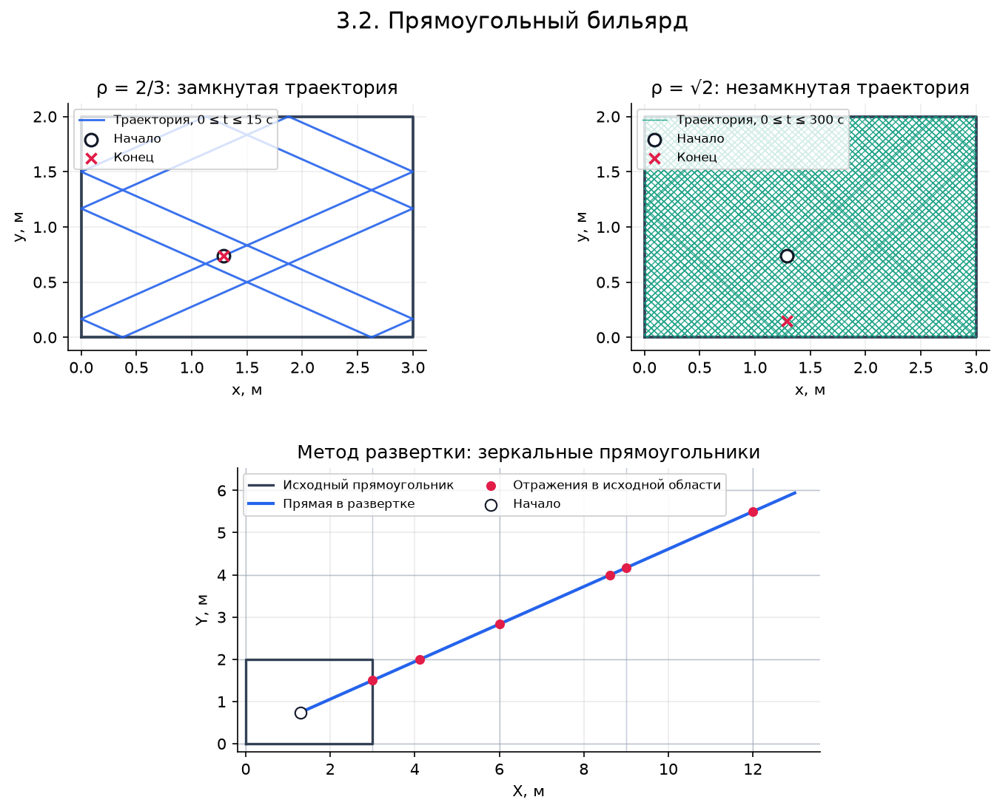

Сохранен рисунок: results/3_2_billiard.png


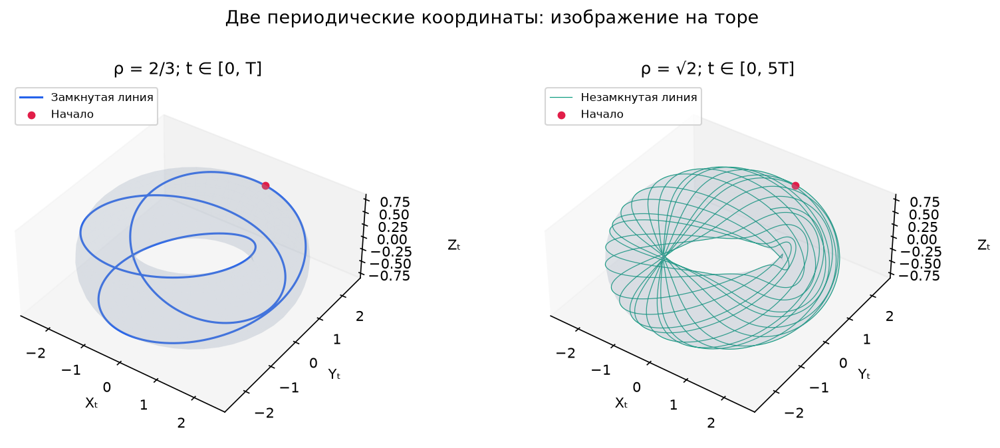

Сохранен рисунок: results/3_2_billiard_torus.png


In [9]:
billiard_fig = plt.figure(figsize=(12, 7.6))
billiard_grid = billiard_fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.44)
for billiard_i, billiard_case in enumerate(billiard_cases):
    billiard_ax = billiard_fig.add_subplot(billiard_grid[0, billiard_i])
    billiard_duration = billiard_period if billiard_i == 0 else 20*billiard_period
    billiard_times = billiard_time_grid(billiard_case, billiard_duration, 8000)
    _, _, billiard_x, billiard_y = billiard_state(billiard_times, billiard_case)
    billiard_draw_boundary(billiard_ax)
    billiard_ax.plot(billiard_x, billiard_y, color=billiard_case['color'],
                     lw=1.4 if billiard_i == 0 else 0.65, alpha=0.9,
                     label=f'Траектория, 0 ≤ t ≤ {billiard_duration:g} с')
    billiard_ax.scatter([billiard_x[0]], [billiard_y[0]], s=65, facecolors='white',
                        edgecolors='#111827', linewidths=1.5, zorder=5, label='Начало')
    billiard_ax.scatter([billiard_x[-1]], [billiard_y[-1]], marker='x', s=45,
                        color='#e11d48', linewidths=1.8, zorder=6, label='Конец')
    billiard_ax.set_title('ρ = 2/3: замкнутая траектория' if billiard_i == 0
                          else 'ρ = √2: незамкнутая траектория')
    billiard_ax.legend(loc='upper left', fontsize=8)

billiard_ax = billiard_fig.add_subplot(billiard_grid[1, :])
billiard_case = billiard_cases[0]
billiard_duration = 0.65*billiard_period
billiard_draw_unfolding(billiard_ax, billiard_case, billiard_duration)
billiard_times = billiard_time_grid(billiard_case, billiard_duration, 300)
billiard_X, billiard_Y, _, _ = billiard_state(billiard_times, billiard_case)
billiard_ax.plot(billiard_X, billiard_Y, color=billiard_case['color'], lw=2,
                 label='Прямая в развертке')
billiard_hit_times = np.sort(np.r_[
    billiard_hits(billiard_case['x0'], billiard_case['vx'], billiard_a, billiard_duration),
    billiard_hits(billiard_case['y0'], billiard_case['vy'], billiard_b, billiard_duration)])
billiard_Xh, billiard_Yh, _, _ = billiard_state(billiard_hit_times, billiard_case)
billiard_ax.scatter(billiard_Xh, billiard_Yh, s=28, color='#e11d48', zorder=4,
                    label='Отражения в исходной области')
billiard_ax.scatter([billiard_X[0]], [billiard_Y[0]], s=55, facecolors='white',
                    edgecolors='#111827', zorder=5, label='Начало')
billiard_ax.set_title('Метод развертки: зеркальные прямоугольники')
billiard_ax.legend(loc='upper left', fontsize=8, ncol=2)
billiard_fig.suptitle('3.2. Прямоугольный бильярд', fontsize=15, y=0.99)
save_figure(billiard_fig, '3_2_billiard')

billiard_torus_fig = plt.figure(figsize=(11, 4.6))
for billiard_i, billiard_case in enumerate(billiard_cases):
    billiard_ax = billiard_torus_fig.add_subplot(1, 2, billiard_i+1, projection='3d')
    billiard_draw_torus(billiard_ax)
    # Явная подпись в координатах оси учитывается при обрезке границ PNG.
    billiard_ax.set_zlabel('')
    billiard_ax.text2D(1.23, 0.54, 'Zₜ', transform=billiard_ax.transAxes,
                       fontsize=10, va='center', clip_on=False)
    billiard_duration = billiard_period if billiard_i == 0 else 5*billiard_period
    billiard_times = np.linspace(0, billiard_duration, 5000)
    billiard_X, billiard_Y, _, _ = billiard_state(billiard_times, billiard_case)
    billiard_xyz = billiard_torus(billiard_X, billiard_Y)
    billiard_ax.plot(*billiard_xyz, color=billiard_case['color'], lw=1.5 if billiard_i == 0 else 0.6,
                     label='Замкнутая линия' if billiard_i == 0 else 'Незамкнутая линия')
    billiard_ax.scatter(*[c[0] for c in billiard_xyz], color='#e11d48', s=22, label='Начало')
    billiard_ax.set_title('ρ = 2/3; t ∈ [0, T]' if billiard_i == 0 else 'ρ = √2; t ∈ [0, 5T]')
    billiard_ax.legend(loc='upper left', fontsize=8)
billiard_torus_fig.suptitle('Две периодические координаты: изображение на торе', fontsize=13)
billiard_torus_fig.tight_layout(pad=1.5)
save_figure(billiard_torus_fig, '3_2_billiard_torus')

### 3.2.6. Проверка решения

Проверяем нахождение точки внутри прямоугольника, сохранение квадрата скорости,
возвращение периодической траектории в исходное **состояние**,
смену знака нормальной скорости и сохранение касательной при ударе.
Проверка возвращения иррациональной траектории в один момент времени сама по себе
не доказывает непериодичность; ее обоснование дано аналитически выше.

In [8]:
for billiard_case in billiard_cases:
    billiard_times = billiard_time_grid(billiard_case, 20*billiard_period, 6001)
    _, _, billiard_x, billiard_y = billiard_state(billiard_times, billiard_case)
    billiard_vx = billiard_component_velocity(billiard_times, billiard_case['x0'],
                                             billiard_case['vx'], billiard_a)
    billiard_vy = billiard_component_velocity(billiard_times, billiard_case['y0'],
                                             billiard_case['vy'], billiard_b)
    assert np.all((billiard_x >= -1e-12) & (billiard_x <= billiard_a+1e-12))
    assert np.all((billiard_y >= -1e-12) & (billiard_y <= billiard_b+1e-12))
    assert np.allclose(billiard_vx**2 + billiard_vy**2,
                       billiard_case['vx']**2 + billiard_case['vy']**2)

billiard_case = billiard_cases[0]
_, _, billiard_x_return, billiard_y_return = billiard_state(billiard_period, billiard_case)
billiard_return_error = np.hypot(billiard_x_return-billiard_case['x0'],
                                billiard_y_return-billiard_case['y0'])
assert billiard_return_error < 1e-12
assert np.isclose(billiard_component_velocity(billiard_period, billiard_case['x0'],
                                              billiard_case['vx'], billiard_a), billiard_case['vx'])
assert np.isclose(billiard_component_velocity(billiard_period, billiard_case['y0'],
                                              billiard_case['vy'], billiard_b), billiard_case['vy'])
billiard_first_hit = billiard_hits(billiard_x0, billiard_vx0, billiard_a, billiard_period)[0]
billiard_hit_window = billiard_first_hit + np.array([-1e-7, 1e-7])
billiard_vx_sides = billiard_component_velocity(billiard_hit_window, billiard_x0,
                                                billiard_case['vx'], billiard_a)
billiard_vy_sides = billiard_component_velocity(billiard_hit_window, billiard_y0,
                                                billiard_case['vy'], billiard_b)
assert np.isclose(billiard_vx_sides[0], -billiard_vx_sides[1])
assert np.isclose(billiard_vy_sides[0], billiard_vy_sides[1])
print(f'Проверки пройдены. Ошибка замыкания периодической траектории: {billiard_return_error:.2e} м.')
print('Энергия сохраняется; при отражении нормальная скорость меняет знак, касательная сохраняется.')

Проверки пройдены. Ошибка замыкания периодической траектории: 1.79e-15 м.
Энергия сохраняется; при отражении нормальная скорость меняет знак, касательная сохраняется.


### 3.2.7. Синхронная анимация

Для каждого направления одновременно показаны исходный прямоугольник, развертка
и тор. Во всех трех окнах одной строки используется один и тот же физический момент $t$.
Синий случай возвращается в исходное состояние при $t=T=15$ с; зеленый продолжает
незамкнутый путь. Стрелка показывает текущую скорость, $N$ обозначает число отражений.
Цветной след построен по точным моментам ударов, поэтому достигает границ без срезания углов.

Слайдер кадров и кнопки воспроизведения/паузы находятся под анимацией.
Скорость воспроизведения служит для просмотра и не изменяет физическое время на экране.

In [10]:
billiard_anim_times = np.linspace(0, billiard_period, ANIM_FRAMES)
billiard_anim_fig = plt.figure(figsize=(12, 7), dpi=75)
billiard_anim_grid = billiard_anim_fig.add_gridspec(2, 3, wspace=0.34, hspace=0.55)
billiard_anim_artists = []

for billiard_row, billiard_case in enumerate(billiard_cases):
    billiard_ax_real = billiard_anim_fig.add_subplot(billiard_anim_grid[billiard_row, 0])
    billiard_ax_unfold = billiard_anim_fig.add_subplot(billiard_anim_grid[billiard_row, 1])
    billiard_ax_torus = billiard_anim_fig.add_subplot(billiard_anim_grid[billiard_row, 2], projection='3d')
    billiard_draw_boundary(billiard_ax_real)
    billiard_draw_unfolding(billiard_ax_unfold, billiard_case, billiard_period)
    billiard_draw_torus(billiard_ax_torus)
    billiard_label = 'ρ = 2/3' if billiard_row == 0 else 'ρ = √2'
    billiard_ax_real.set_title(f'{billiard_label}: бильярд', fontsize=10)
    billiard_ax_unfold.set_title('Развертка', fontsize=10)
    billiard_ax_torus.set_title('Движение на торе', fontsize=10)

    # Сетка следа включает все кадры и точные времена отражений.
    billiard_trace_t = np.unique(np.r_[billiard_time_grid(billiard_case, billiard_period, 700),
                                        billiard_anim_times])
    billiard_trace_X, billiard_trace_Y, billiard_trace_x, billiard_trace_y = billiard_state(
        billiard_trace_t, billiard_case)
    billiard_trace_xyz = billiard_torus(billiard_trace_X, billiard_trace_Y)
    billiard_line_real, = billiard_ax_real.plot([], [], color=billiard_case['color'], lw=1.3)
    billiard_dot_real, = billiard_ax_real.plot([], [], 'o', color=billiard_case['color'], ms=7)
    billiard_arrow = billiard_ax_real.quiver([billiard_x0], [billiard_y0], [billiard_case['vx']],
                                            [billiard_case['vy']], angles='xy', scale_units='xy',
                                            scale=3, color='#e11d48', width=0.009)
    billiard_text = billiard_ax_real.text(0.025, 0.97, '', transform=billiard_ax_real.transAxes,
                                         fontsize=7.5, va='top', zorder=8,
                                         bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
    billiard_line_unfold, = billiard_ax_unfold.plot([], [], color=billiard_case['color'], lw=1.8)
    billiard_dot_unfold, = billiard_ax_unfold.plot([], [], 'o', color=billiard_case['color'], ms=6)
    billiard_line_torus, = billiard_ax_torus.plot([], [], [], color=billiard_case['color'], lw=1.6)
    billiard_dot_torus, = billiard_ax_torus.plot([], [], [], 'o', color='#e11d48', ms=5)
    billiard_hits_x = billiard_hits(billiard_case['x0'], billiard_case['vx'], billiard_a, billiard_period)
    billiard_hits_y = billiard_hits(billiard_case['y0'], billiard_case['vy'], billiard_b, billiard_period)
    billiard_anim_artists.append(dict(
        case=billiard_case, t=billiard_trace_t, X=billiard_trace_X, Y=billiard_trace_Y,
        x=billiard_trace_x, y=billiard_trace_y, xyz=billiard_trace_xyz,
        line_real=billiard_line_real, dot_real=billiard_dot_real, arrow=billiard_arrow,
        text=billiard_text, line_unfold=billiard_line_unfold, dot_unfold=billiard_dot_unfold,
        line_torus=billiard_line_torus, dot_torus=billiard_dot_torus,
        hits=np.sort(np.r_[billiard_hits_x, billiard_hits_y])))

billiard_anim_fig.suptitle('3.2. Упругие отражения, развертка и тор', fontsize=13, y=0.99)
billiard_anim_fig.subplots_adjust(bottom=0.12, top=0.89)


def billiard_update(frame):
    t = billiard_anim_times[frame]
    for art in billiard_anim_artists:
        case = art['case']
        n = np.searchsorted(art['t'], t, side='right')
        X, Y, x, y = billiard_state(t, case)
        vx = float(billiard_component_velocity(t, case['x0'], case['vx'], billiard_a))
        vy = float(billiard_component_velocity(t, case['y0'], case['vy'], billiard_b))
        art['line_real'].set_data(art['x'][:n], art['y'][:n])
        art['dot_real'].set_data([x], [y])
        art['arrow'].set_offsets([[x, y]])
        art['arrow'].set_UVC([vx], [vy])
        art['line_unfold'].set_data(art['X'][:n], art['Y'][:n])
        art['dot_unfold'].set_data([X], [Y])
        art['line_torus'].set_data_3d(*[c[:n] for c in art['xyz']])
        art['dot_torus'].set_data_3d(*[[float(c)] for c in billiard_torus(X, Y)])
        count = np.searchsorted(art['hits'], t, side='right')
        art['text'].set_text(f't = {t:5.2f} с; x = {float(x):.2f} м; y = {float(y):.2f} м\n'
                             f'vₓ = {vx:+.2f}; vᵧ = {vy:+.2f} м/с; N = {count}')
    return ()  # 3D-ось перерисовывается целиком: blit=False.


billiard_animation = FuncAnimation(billiard_anim_fig, billiard_update,
                                    frames=len(billiard_anim_times), interval=1000/ANIM_FPS,
                                    blit=False, repeat=True)
display_animation(billiard_animation)

Сохранен автономный плеер: results/animation_03.html


**Вывод по задаче 3.2.** Формула треугольной волны дает точное положение точки при
всех обычных отражениях. Рациональность нормированного отношения компонент скорости
определяет периодичность. Иррациональное направление дает незамкнутую плотную траекторию
на соответствующем торе, при этом сам прямоугольный бильярд остается интегрируемой системой.

## 3.3. Цепная линия

**Задача.** Найти форму равновесия однородной гибкой тяжелой нерастяжимой цепи, подвешенной за два конца. Ось $x$ направлена горизонтально, ось $y$ — вверх. Линейная плотность $\lambda$ постоянна **на единицу длины самой цепи**, а не ее горизонтальной проекции. Вес единицы длины равен $w=\lambda g$.

### 3.3.1. Равновесие элемента и дифференциальное уравнение

Цепь не сопротивляется изгибу, поэтому сила натяжения направлена по касательной. Обозначим через $T$ ее модуль, а через $\alpha$ угол касательной с осью $x$:

$$H=T\cos\alpha,\qquad V=T\sin\alpha,\qquad y'=\tan\alpha=\frac{V}{H}.$$

Для элемента длины $ds=\sqrt{1+(y')^2}\,dx$ уравнения равновесия имеют вид

$$dH=0,\qquad dV-w\,ds=0.$$

Следовательно, горизонтальная составляющая $H>0$ постоянна по всей цепи. Поскольку $V=Hy'$, получаем

$$H y''\,dx=w\sqrt{1+(y')^2}\,dx,$$

или

$$\boxed{y''=\frac{1}{a}\sqrt{1+(y')^2}},\qquad
\boxed{a=\frac{H}{\lambda g}}>0.$$

Здесь $a$ имеет размерность длины. Уравнение параболы получилось бы для постоянной нагрузки **на единицу горизонтальной проекции**; для однородной свободно висящей цепи нагрузка пропорциональна $ds$.

### 3.3.2. Решение методом разделения переменных

Положим $p=y'$. Тогда

$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a},\qquad
\operatorname{arsinh}p=\frac{x-x_c}{a}.$$

Отсюда

$$y'=\sinh\frac{x-x_c}{a},\qquad
\boxed{y(x)=a\cosh\frac{x-x_c}{a}+C}.$$

Постоянная $x_c$ задает положение самой низкой точки, а $C$ — вертикальный сдвиг. При выборе $x_c=0$, $C=0$ получаем требуемый вид

$$\boxed{y=a\,\operatorname{ch}\frac{x}{a}}
\quad\text{где }\operatorname{ch}u=\cosh u.$$

### 3.3.3. Геометрические и физические свойства

Если отсчитывать **знаковую** длину дуги от самой низкой точки, то

$$s(x)=\int_{x_c}^{x}\sqrt{1+(y')^2}\,d\xi
=a\sinh\frac{x-x_c}{a}.$$

Натяжение и радиус кривизны равны

$$T(x)=H\sqrt{1+(y')^2}
=H\cosh\frac{x-x_c}{a}
=\lambda g\sqrt{a^2+s^2},$$

$$R(x)=\frac{(1+(y')^2)^{3/2}}{y''}
=a\cosh^2\frac{x-x_c}{a}.$$

В нижней точке $T_{\min}=H=\lambda ga$ и $R_{\min}=a$. Поэтому увеличение $a$ означает более пологую цепную линию и большее горизонтальное натяжение при той же плотности. Для $|x-x_c|\ll a$ цепная линия близка к параболе:

$$y\approx a+C+\frac{(x-x_c)^2}{2a}.$$

### 3.3.4. Закрепление концов, длина и провисание

Пусть опоры находятся в точках $(-d/2,0)$ и $(d/2,0)$. По симметрии $x_c=0$, поэтому

$$\boxed{y(x)=a\left(\cosh\frac{x}{a}-\cosh\frac{d}{2a}\right)}.$$

Провисание $\delta$ — расстояние от уровня опор до нижней точки, а полная длина цепи $L$ равна

$$\boxed{\delta=a\left(\cosh\frac{d}{2a}-1\right)},\qquad
\boxed{L=2a\sinh\frac{d}{2a}}.$$

При $L>d$ последнее уравнение единственным образом определяет $a$. При $L<d$ подвесить цепь между данными опорами невозможно; случай $L=d$ — предельная горизонтальная конфигурация, требующая неограниченного натяжения в модели тяжелой гибкой цепи.

**Уточнение для анимации.** Если одновременно зафиксированы нерастяжимая длина $L$ и обе опоры, форма уже определена. Изменение плотности тогда меняет $H=\lambda ga$, но не форму. Чтобы показать изменение формы при варьировании $H$ и $\lambda$, ниже рассматривается **семейство разных равновесных цепей** между одними опорами: необходимая длина $L$ вычисляется и показывается для каждого кадра. Это последовательность равновесий, а не расчет колебаний одной цепи.

Для этого семейства при фиксированных $d$:

- увеличение $H$ при фиксированной $\lambda$ увеличивает $a$ и уменьшает провисание;
- увеличение $\lambda$ при фиксированном $H$ уменьшает $a$ и увеличивает провисание.

При малом провисании $d/a\ll1$:

$$\delta\approx\frac{d^2}{8a}=\frac{\lambda g d^2}{8H}.$$

In [11]:
# Базовые формулы и пример краевой задачи: пролет 4 м, длина цепи 5 м.
catenary_span = 4.0      # d, м
catenary_length = 5.0    # L, м
catenary_density = 1.0   # lambda, кг/м


def catenary_y(x, a, span=catenary_span):
    """Цепь между опорами (-d/2, 0), (d/2, 0)."""
    return a * (np.cosh(np.asarray(x) / a) - np.cosh(span / (2 * a)))


def catenary_sag(a, span=catenary_span):
    return a * (np.cosh(span / (2 * a)) - 1.0)


def catenary_total_length(a, span=catenary_span):
    return 2 * a * np.sinh(span / (2 * a))


# Функция L(a) убывает. Интервал выбран для конкретных данных примера.
catenary_root = root_scalar(
    lambda a: catenary_total_length(a) - catenary_length,
    bracket=(0.2, 100.0), method="brentq", xtol=1e-12,
)
assert catenary_root.converged
catenary_a = catenary_root.root
catenary_H = catenary_density * G * catenary_a
catenary_x = np.linspace(-catenary_span / 2, catenary_span / 2, 401)
catenary_tension = catenary_H * np.cosh(catenary_x / catenary_a)

print(f"Параметр a = {catenary_a:.6f} м")
print(f"Провисание = {catenary_sag(catenary_a):.6f} м")
print(f"Длина цепи = {catenary_total_length(catenary_a):.6f} м")
print(f"Натяжение в нижней точке H = {catenary_H:.6f} Н")
print(f"Натяжение у каждой опоры = {catenary_tension[0]:.6f} Н")

# Проверки условий на концах, длины и вертикальных реакций опор.
assert np.allclose(catenary_y(np.array([-2.0, 2.0]), catenary_a), 0.0)
assert np.isclose(catenary_total_length(catenary_a), catenary_length)
assert np.isclose(
    2 * catenary_H * np.sinh(catenary_span / (2 * catenary_a)),
    catenary_density * G * catenary_length,
)
print("Проверка: сумма вертикальных реакций равна весу цепи.")

Параметр a = 1.691009 м
Провисание = 1.327188 м
Длина цепи = 5.000000 м
Натяжение в нижней точке H = 16.588802 Н
Натяжение у каждой опоры = 29.608512 Н
Проверка: сумма вертикальных реакций равна весу цепи.


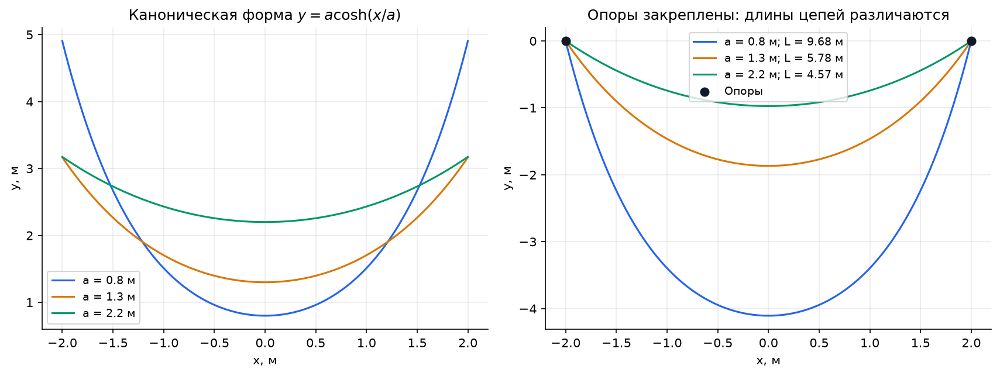

Сохранен рисунок: results/3_3_catenary_shapes.png


In [12]:
# Два вида одной формулы: без сдвига и с концами на одном уровне.
catenary_fig1, catenary_axes1 = plt.subplots(1, 2, figsize=(11.5, 4.4))
catenary_colors = ["#2563eb", "#d97706", "#059669"]
for catenary_ai, catenary_color in zip([0.8, 1.3, 2.2], catenary_colors):
    catenary_axes1[0].plot(
        catenary_x, catenary_ai * np.cosh(catenary_x / catenary_ai),
        color=catenary_color, label=f"a = {catenary_ai:.1f} м",
    )
    catenary_axes1[1].plot(
        catenary_x, catenary_y(catenary_x, catenary_ai),
        color=catenary_color,
        label=f"a = {catenary_ai:.1f} м; L = {catenary_total_length(catenary_ai):.2f} м",
    )
catenary_axes1[0].set_title(r"Каноническая форма $y=a\cosh(x/a)$")
catenary_axes1[1].set_title("Опоры закреплены: длины цепей различаются")
catenary_axes1[1].scatter([-2, 2], [0, 0], color="#111827", s=45, zorder=5,
                         label="Опоры")
for catenary_ax in catenary_axes1:
    catenary_ax.set(xlabel="x, м", ylabel="y, м")
    catenary_ax.grid(True, alpha=0.25)
    catenary_ax.legend(fontsize=9)
catenary_fig1.tight_layout()
save_figure(catenary_fig1, "3_3_catenary_shapes")

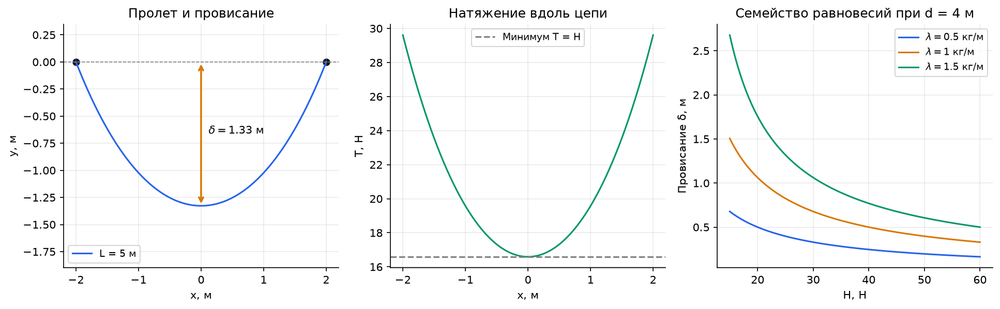

Сохранен рисунок: results/3_3_catenary_properties.png


In [13]:
# Геометрия конкретной цепи и зависимость провисания от H и плотности.
catenary_fig2, catenary_axes2 = plt.subplots(1, 3, figsize=(13, 4.1))
catenary_axes2[0].plot(catenary_x, catenary_y(catenary_x, catenary_a),
                       color="#2563eb", label=f"L = {catenary_length:g} м")
catenary_axes2[0].scatter([-2, 2], [0, 0], color="#111827", s=35)
catenary_axes2[0].axhline(0, color="gray", lw=0.8, ls="--")
catenary_axes2[0].annotate(
    "", xy=(0, 0), xytext=(0, -catenary_sag(catenary_a)),
    arrowprops={"arrowstyle": "<->", "color": "#d97706", "lw": 1.7},
)
catenary_axes2[0].text(0.12, -catenary_sag(catenary_a) / 2,
                        rf"$\delta={catenary_sag(catenary_a):.2f}$ м",
                        fontsize=10)
catenary_axes2[0].set_title("Пролет и провисание")
catenary_axes2[0].set(xlabel="x, м", ylabel="y, м", ylim=(-1.9, 0.35))
catenary_axes2[0].legend(fontsize=9, loc="lower left")

catenary_axes2[1].plot(catenary_x, catenary_tension, color="#059669")
catenary_axes2[1].axhline(catenary_H, color="gray", ls="--", label="Минимум T = H")
catenary_axes2[1].set_title("Натяжение вдоль цепи")
catenary_axes2[1].set(xlabel="x, м", ylabel="T, Н")
catenary_axes2[1].legend(fontsize=9)

catenary_H_grid = np.linspace(15.0, 60.0, 300)
for catenary_rho, catenary_color in zip([0.5, 1.0, 1.5], catenary_colors):
    catenary_axes2[2].plot(
        catenary_H_grid, catenary_sag(catenary_H_grid / (catenary_rho * G)),
        color=catenary_color, label=rf"$\lambda={catenary_rho:g}$ кг/м",
    )
catenary_axes2[2].set_title("Семейство равновесий при d = 4 м")
catenary_axes2[2].set(xlabel="H, Н", ylabel="Провисание δ, м")
catenary_axes2[2].legend(fontsize=9)
for catenary_ax in catenary_axes2:
    catenary_ax.grid(True, alpha=0.25)
catenary_fig2.tight_layout()
save_figure(catenary_fig2, "3_3_catenary_properties")

### 3.3.5. Силы на конечном элементе цепи

Для участка от $x_1$ до $x_2$ длина и действующие на него силы равны

$$\Delta s=a\left(\sinh\frac{x_2}{a}-\sinh\frac{x_1}{a}\right),$$

$$\mathbf T_1=(-H,-H y'(x_1)),\qquad
\mathbf T_2=(H,H y'(x_2)),\qquad
\mathbf P=(0,-\lambda g\Delta s).$$

Проверка равновесия получается непосредственно из $H=\lambda ga$:

$$\mathbf T_1+\mathbf T_2+\mathbf P=\mathbf0.$$

В анимации натяжения приложены к концам выделенного участка, а его вес — к центру масс. Один и тот же масштаб сил сохранен во всех кадрах. В первой половине анимации изменяется $H$ при постоянной $\lambda$, во второй — $\lambda$ при постоянном $H$. Панель воспроизведения позволяет ставить анимацию на паузу и переходить к отдельному кадру.

In [14]:
# Точный центр масс и силы конечного участка однородной цепи.
def catenary_element(a, H, density, x1=0.25, x2=1.0):
    u1, u2 = x1 / a, x2 / a
    ds = a * (np.sinh(u2) - np.sinh(u1))
    C = -a * np.cosh(catenary_span / (2 * a))
    # Первообразные интегралов x ds и y ds.
    def first_x(x, u):
        return a * x * np.sinh(u) - a**2 * np.cosh(u)
    def first_y(u):
        return a**2 * (u / 2 + np.sinh(2 * u) / 4) + C * a * np.sinh(u)
    center = np.array([
        (first_x(x2, u2) - first_x(x1, u1)) / ds,
        (first_y(u2) - first_y(u1)) / ds,
    ])
    left = np.array([x1, catenary_y(x1, a)])
    right = np.array([x2, catenary_y(x2, a)])
    forces = np.array([
        [-H, -H * np.sinh(u1)],
        [ H,  H * np.sinh(u2)],
        [0.0, -density * G * ds],
    ])
    return np.array([left, right, center]), forces, ds


catenary_nframes = min(ANIM_FRAMES, 100)
catenary_phase = np.linspace(0.0, 1.0, catenary_nframes)
catenary_H_frames = np.full(catenary_nframes, 18.0)
catenary_rho_frames = np.full(catenary_nframes, 1.0)
catenary_first_half = catenary_phase <= 0.5
catenary_H_frames[catenary_first_half] *= (
    1 + 0.4 * np.sin(2 * np.pi * catenary_phase[catenary_first_half])**2
)
catenary_rho_frames[~catenary_first_half] *= (
    1 + 0.4 * np.sin(2 * np.pi * (catenary_phase[~catenary_first_half] - 0.5))**2
)
catenary_a_frames = catenary_H_frames / (catenary_rho_frames * G)

# Для всех кадров проверяем силу и момент сил относительно начала координат.
for catenary_ai, catenary_hi, catenary_ri in zip(
    catenary_a_frames, catenary_H_frames, catenary_rho_frames
):
    catenary_positions, catenary_forces, _ = catenary_element(
        catenary_ai, catenary_hi, catenary_ri
    )
    assert np.allclose(catenary_forces.sum(axis=0), 0.0, atol=1e-10)
    catenary_moment = np.sum(
        catenary_positions[:, 0] * catenary_forces[:, 1]
        - catenary_positions[:, 1] * catenary_forces[:, 0]
    )
    assert abs(catenary_moment) < 1e-10
print("Во всех кадрах сумма сил и сумма моментов сил на элементе равны нулю.")

Во всех кадрах сумма сил и сумма моментов сил на элементе равны нулю.


In [15]:
# Анимация семейства статических равновесий.
catenary_fig_anim, catenary_ax_anim = plt.subplots(
    1, 2, figsize=(11.2, 4.8), dpi=75,
)
catenary_fig_anim.subplots_adjust(top=0.84, bottom=0.20, wspace=0.30)
catenary_fig_anim.suptitle("Цепная линия: семейство равновесий", fontsize=14)
catenary_segment_x = np.linspace(0.25, 1.0, 70)
catenary_line, = catenary_ax_anim[0].plot([], [], color="#2563eb", lw=2.5,
                                          label="Цепь")
catenary_segment, = catenary_ax_anim[0].plot([], [], color="#d97706", lw=4,
                                             label="Выделенный элемент")
catenary_ax_anim[0].scatter([-2, 2], [0, 0], color="#111827", s=35)
catenary_ax_anim[0].axhline(0, color="gray", ls="--", lw=0.8)
catenary_ax_anim[0].set(xlim=(-2.4, 2.4), ylim=(-2.6, 0.4),
                         xlabel="x, м", ylabel="y, м", title="Форма и провисание")
catenary_ax_anim[0].legend(loc="lower left", fontsize=8)
catenary_element_line, = catenary_ax_anim[1].plot([], [], color="#d97706", lw=4)
catenary_ax_anim[1].set(xlim=(-1.25, 2.5), ylim=(-2.9, 0.9),
                         xlabel="x, м", ylabel="y, м", title="Силы на элементе")
catenary_ax_anim[1].set_aspect("equal", adjustable="box")
catenary_force_scale = 0.045  # 0.045 метра изображения на 1 ньютон.
catenary_arrows = []
for catenary_color in ("#059669", "#059669", "#dc2626"):
    catenary_arrows.append(catenary_ax_anim[1].annotate(
        "", xy=(0, 0), xytext=(0, 0),
        arrowprops={"arrowstyle": "-|>", "color": catenary_color, "lw": 2.0},
    ))
catenary_force_labels = [
    catenary_ax_anim[1].text(0, 0, catenary_label, fontsize=10)
    for catenary_label in (r"$\mathbf{T}_1$", r"$\mathbf{T}_2$", r"$\mathbf{P}$")
]
catenary_cg, = catenary_ax_anim[1].plot([], [], "o", color="#111827", ms=4)
catenary_info = catenary_fig_anim.text(0.07, 0.075, "", fontsize=10, va="center")
for catenary_ax in catenary_ax_anim:
    catenary_ax.grid(True, alpha=0.25)


def catenary_update(frame):
    a = catenary_a_frames[frame]
    H = catenary_H_frames[frame]
    density = catenary_rho_frames[frame]
    catenary_line.set_data(catenary_x, catenary_y(catenary_x, a))
    segment_y = catenary_y(catenary_segment_x, a)
    catenary_segment.set_data(catenary_segment_x, segment_y)
    catenary_element_line.set_data(catenary_segment_x, segment_y)
    positions, forces, ds = catenary_element(a, H, density)
    for arrow, label, start, force in zip(
        catenary_arrows, catenary_force_labels, positions, forces
    ):
        tip = start + catenary_force_scale * force
        arrow.set_position(start)
        arrow.xy = tuple(tip)
        label.set_position(tip + np.array([0.06, 0.04]))
    catenary_cg.set_data([positions[2, 0]], [positions[2, 1]])
    stage = "Изменяется H; плотность постоянна" if catenary_first_half[frame] else (
        "Изменяется плотность; H постоянно"
    )
    catenary_info.set_text(
        f"{stage}.  H = {H:.2f} Н; λ = {density:.2f} кг/м; a = {a:.3f} м\n"
        f"Провисание δ = {catenary_sag(a):.3f} м; длина L = "
        f"{catenary_total_length(a):.3f} м; |ΣF| = {np.linalg.norm(forces.sum(axis=0)):.1e} Н"
    )
    return catenary_line, catenary_segment, catenary_element_line, catenary_info


catenary_update(0)
catenary_animation = FuncAnimation(
    catenary_fig_anim, catenary_update, frames=catenary_nframes,
    interval=1000 / ANIM_FPS, blit=False, repeat=True,
)
display_animation(catenary_animation)

Сохранен автономный плеер: results/animation_04.html


**Вывод.** Однородная гибкая цепь принимает форму $y=a\cosh((x-x_c)/a)+C$, где $a=H/(\lambda g)$. Полученные графики показывают влияние этого параметра на провисание, а анимация связывает изменение формы с натяжением, плотностью и требуемой длиной. Равновесие выделенного элемента проверено как по силам, так и по моментам сил.

<a id="task-34"></a>
## 3.4. Таутохрона: одинаковое время спуска

**Задача.** Найти кривую, по которой материальная точка, отпущенная **без начальной скорости**, за одно и то же время $T_*$ достигает нижней точки независимо от начальной высоты. Трение отсутствует, $g$ постоянно, реакция гладкой направляющей работы не совершает. Нарисованные ниже шарики обозначают материальные точки; вращательная энергия твердого шарика в эту модель не входит.

Ось $y$ направим вверх, нижнюю точку поместим в начало координат. Сначала рассмотрим правую ветвь кривой: $h>0$ — начальная высота, $s(y)$ — длина дуги от минимума до высоты $y$, $s(0)=0$. На этой ветви высота монотонно растет вместе с длиной дуги.

### 3.4.1. Интегральное уравнение для времени

Из закона сохранения энергии при старте с высоты $h$:

$$\frac{mv^2}{2}+mgy=mgh,
\qquad v=\sqrt{2g(h-y)}.$$

Поэтому время спуска равно

$$T(h)=\int_0^h\frac{s'(y)\,dy}{\sqrt{2g(h-y)}}.$$

Требование $T(h)=T_*$ приводит к **интегральному уравнению Абеля**:

$$\boxed{\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy
=\sqrt{2g}\,T_*.}$$

Корневая особенность при $y=h$ интегрируема: точка начинает движение из состояния покоя.

### 3.4.2. Решение уравнения Абеля

Обозначим $C=\sqrt{2g}\,T_*$. Умножим обе части уравнения на $(H-h)^{-1/2}$ и проинтегрируем по $h$ от $0$ до $H$:

$$\int_0^H\frac{dh}{\sqrt{H-h}}
\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy
=2C\sqrt H.$$

Поменяв порядок интегрирования по треугольной области $0\le y\le h\le H$, получим

$$\int_0^H s'(y)
\left[\int_y^H\frac{dh}{\sqrt{(h-y)(H-h)}}\right]dy
=2C\sqrt H.$$

Во внутреннем интеграле положим $h=y+(H-y)\sin^2\varphi$. Тогда

$$\int_y^H\frac{dh}{\sqrt{(h-y)(H-h)}}
=2\int_0^{\pi/2}d\varphi=\pi.$$

Следовательно, $\pi[s(H)-s(0)]=2C\sqrt H$ и

$$\boxed{s(y)=\frac{2T_*\sqrt{2g}}{\pi}\sqrt y.}$$

Введем положительный параметр

$$\boxed{R=\frac{gT_*^2}{\pi^2}.}$$

Тогда зависимость высоты от длины дуги принимает особенно простой вид:

$$\boxed{y=\frac{s^2}{8R}},\qquad
\frac{dy}{ds}=\frac{s}{4R}.$$

Поскольку $|dy/ds|\le1$, регулярная часть ветви имеет $0\le s<4R$, то есть $0\le y<2R$. Для левой ветви вводим отрицательную длину дуги: $-4R<s\le0$.

### 3.4.3. Параметрические уравнения циклоиды

Из $ds^2=dx^2+dy^2$, выбирая $x$ возрастающим с $s$, имеем

$$\frac{dx}{ds}=\sqrt{1-\frac{s^2}{16R^2}}.$$

Положим

$$s=4R\sin\frac{u}{2},\qquad -\pi<u<\pi.$$

Тогда $ds/du=2R\cos(u/2)$ и

$$\frac{dx}{du}
=2R\cos^2\frac{u}{2}=R(1+\cos u).$$

Интегрирование с условием $x(0)=0$ дает

$$\boxed{\begin{aligned}
x(u)&=R(u+\sin u),\\
y(u)&=R(1-\cos u),\qquad -\pi<u<\pi.
\end{aligned}}$$

Это перевернутая арка **циклоиды** с минимумом при $u=0$ и остриями при $u=\pm\pi$. В координатах, где минимум находится в начале, обычная параметризация циклоиды отличается сдвигом и отражением.

**Геометрическое построение.** Окружность радиуса $R$ катится без скольжения под горизонтальной прямой $y=2R$. Ее центр находится в точке $C=(Ru,R)$. Радиус к отмеченной точке равен $(R\sin u,-R\cos u)$, поэтому отмеченная точка имеет именно координаты $(x(u),y(u))$. При увеличении $u$ центр движется вправо, а окружность поворачивается против часовой стрелки. Верхняя точка контакта в каждый момент имеет нулевую скорость.

### 3.4.4. Доказательство таутохронности и закон движения

В качестве координаты возьмем **знаковую** длину дуги $s$ от нижней точки. Тангенциальная составляющая силы тяжести дает

$$m\ddot s=-mg\frac{dy}{ds}
=-\frac{mg}{4R}s.$$

Следовательно, движение вдоль циклоиды описывается точным уравнением гармонического осциллятора:

$$\ddot s+\omega_c^2s=0,\qquad
\omega_c=\sqrt{\frac{g}{4R}}.$$

Для начальных условий $s(0)=s_0\ne0$, $\dot s(0)=0$:

$$s(t)=s_0\cos(\omega_c t),\qquad
\dot s(t)=-\omega_c s_0\sin(\omega_c t).$$

Первое достижение минимума происходит при $\omega_c T_*=\pi/2$:

$$\boxed{T_*=\pi\sqrt{\frac{R}{g}}.}$$

Время не зависит от $s_0$, а значит, и от начальной высоты $h=s_0^2/(8R)$. В частности,

$$y(t)=h\cos^2(\omega_c t),\qquad
u(t)=2\arcsin\frac{s(t)}{4R}.$$

Для анимации вычисляем $u(t)$ по этой формуле и подставляем в $(x(u),y(u))$. Так все точки приходят в минимум одновременно без погрешности пошагового интегрирования. Полный период колебаний равен $4T_*$.

**Границы утверждения.** Рассматриваются ненулевые начальные положения $0<|s_0|<4R$, то есть старт ниже острий и выше минимума. Точка, изначально находящаяся в минимуме, уже прибыла туда; для нее время первого достижения равно нулю. Старт точно в острие исключен из регулярной модели. Таутохронность здесь относится к старту из покоя.

In [15]:
# Радиус образующей окружности и начальные положения четырех точек.
taut_R = 1.0  # м
assert taut_R > 0
taut_omega = np.sqrt(G / (4.0 * taut_R))
taut_T = np.pi * np.sqrt(taut_R / G)
taut_u0 = np.array([-2.60, -1.65, 1.00, 2.20])
assert np.all((np.abs(taut_u0) > 0) & (np.abs(taut_u0) < np.pi))
taut_s0 = 4.0 * taut_R * np.sin(taut_u0 / 2.0)
taut_h0 = taut_R * (1.0 - np.cos(taut_u0))
taut_colors = ['#2667a6', '#e17c24', '#8b5ca6', '#22806b']


def taut_xy(u):
    """Координаты циклоиды с минимумом (0, 0)."""
    u = np.asarray(u)
    return taut_R * (u + np.sin(u)), taut_R * (1.0 - np.cos(u))


def taut_xy_from_s(s):
    """Переход от знаковой длины дуги к координатам точки."""
    s = np.asarray(s)
    if np.any(np.abs(s) > 4.0 * taut_R + 1e-12):
        raise ValueError('Длина дуги выходит за границы одной арки циклоиды.')
    u = 2.0 * np.arcsin(np.clip(s / (4.0 * taut_R), -1.0, 1.0))
    return taut_xy(u)


taut_u_grid = np.linspace(-np.pi, np.pi, 700)
taut_curve_x, taut_curve_y = taut_xy(taut_u_grid)
taut_t_grid = np.linspace(0.0, taut_T, 350)
taut_s_grid = taut_s0[:, None] * np.cos(taut_omega * taut_t_grid)
taut_y_grid = taut_s_grid**2 / (8.0 * taut_R)
print(f'R = {taut_R:.2f} м; время спуска T* = {taut_T:.6f} с')
print(f'Полный период колебаний = {4 * taut_T:.6f} с')

R = 1.00 м; время спуска T* = 1.003033 с
Полный период колебаний = 4.012133 с


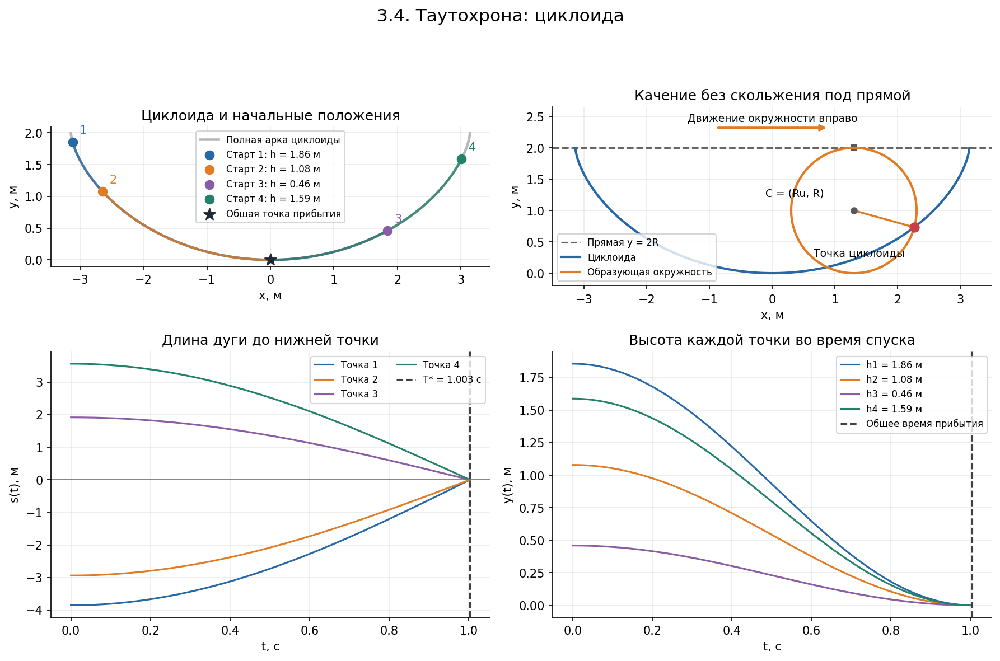

Сохранен рисунок: results/34_tautochrone.png


In [16]:
# Статические иллюстрации: траектории, геометрия и совпадение времен.
taut_fig, taut_axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Одни и те же направляющие, разные стартовые высоты.
taut_ax = taut_axes[0, 0]
taut_ax.plot(taut_curve_x, taut_curve_y, color='0.72', lw=2.2,
             label='Полная арка циклоиды')
for taut_i, (taut_start, taut_color) in enumerate(zip(taut_u0, taut_colors), 1):
    taut_part_u = np.linspace(taut_start, 0.0, 180)
    taut_part_x, taut_part_y = taut_xy(taut_part_u)
    taut_ax.plot(taut_part_x, taut_part_y, color=taut_color, lw=2, alpha=0.8)
    taut_ax.scatter(taut_part_x[0], taut_part_y[0], color=taut_color,
                    s=55, zorder=5, label=f'Старт {taut_i}: h = {taut_part_y[0]:.2f} м')
    taut_ax.annotate(str(taut_i), (taut_part_x[0], taut_part_y[0]),
                     xytext=(6, 7), textcoords='offset points', color=taut_color)
taut_ax.scatter([0], [0], color='#202a35', marker='*', s=110,
                zorder=6, label='Общая точка прибытия')
taut_ax.set(title='Циклоида и начальные положения', xlabel='x, м', ylabel='y, м')
taut_ax.set_aspect('equal', adjustable='box')
taut_ax.legend(fontsize=8, loc='upper center')

# 2. Окружность катится по нижней стороне горизонтальной прямой.
taut_ax = taut_axes[0, 1]
taut_u_geom = 1.30
taut_center = np.array([taut_R * taut_u_geom, taut_R])
taut_phi = np.linspace(0, 2 * np.pi, 200)
taut_ax.axhline(2 * taut_R, color='0.40', lw=1.5, ls='--', label='Прямая y = 2R')
taut_ax.plot(taut_curve_x, taut_curve_y, color='#2667a6', lw=2, label='Циклоида')
taut_ax.plot(taut_center[0] + taut_R * np.cos(taut_phi),
             taut_center[1] + taut_R * np.sin(taut_phi),
             color='#e17c24', lw=2, label='Образующая окружность')
taut_point_x, taut_point_y = taut_xy(taut_u_geom)
taut_ax.plot([taut_center[0], taut_point_x], [taut_center[1], taut_point_y],
             color='#e17c24', lw=1.7)
taut_ax.scatter([taut_center[0]], [taut_center[1]], color='0.35', s=25, zorder=5)
taut_ax.scatter([taut_point_x], [taut_point_y], color='#c83f49', s=60, zorder=6)
taut_ax.scatter([taut_center[0]], [2 * taut_R], color='0.35', marker='s', s=25)
taut_ax.annotate('C = (Ru, R)', taut_center, xytext=(-76, 12),
                 textcoords='offset points', fontsize=9)
taut_ax.annotate('Точка циклоиды', (taut_point_x, taut_point_y), xytext=(-8, -25),
                 textcoords='offset points', fontsize=9, ha='right')
taut_ax.annotate('', xy=(0.9 * taut_R, 2.32 * taut_R),
                 xytext=(-0.9 * taut_R, 2.32 * taut_R),
                 arrowprops={'arrowstyle': '->', 'color': '#e17c24', 'lw': 2})
taut_ax.text(0, 2.42 * taut_R, 'Движение окружности вправо', ha='center', fontsize=9)
taut_ax.set(xlim=(-3.5 * taut_R, 3.5 * taut_R), ylim=(-0.2 * taut_R, 2.65 * taut_R),
             title='Качение без скольжения под прямой', xlabel='x, м', ylabel='y, м')
taut_ax.set_aspect('equal', adjustable='box')
taut_ax.legend(fontsize=8, loc='lower left')

# 3. Знаковая длина дуги всех точек обращается в ноль при одном T*.
taut_ax = taut_axes[1, 0]
for taut_i, taut_color in enumerate(taut_colors):
    taut_ax.plot(taut_t_grid, taut_s_grid[taut_i], color=taut_color,
                 label=f'Точка {taut_i + 1}')
taut_ax.axhline(0.0, color='0.45', lw=0.8)
taut_ax.axvline(taut_T, color='0.25', ls='--', label=f'T* = {taut_T:.3f} с')
taut_ax.set(title='Длина дуги до нижней точки', xlabel='t, с', ylabel='s(t), м')
taut_ax.legend(fontsize=8, ncol=2)

# 4. Спуск с различных начальных высот.
taut_ax = taut_axes[1, 1]
for taut_i, taut_color in enumerate(taut_colors):
    taut_ax.plot(taut_t_grid, taut_y_grid[taut_i], color=taut_color,
                 label=f'h{taut_i + 1} = {taut_h0[taut_i]:.2f} м')
taut_ax.axvline(taut_T, color='0.25', ls='--', label='Общее время прибытия')
taut_ax.set(title='Высота каждой точки во время спуска', xlabel='t, с', ylabel='y(t), м')
taut_ax.legend(fontsize=8)
for taut_ax in taut_axes.flat:
    taut_ax.grid(True, alpha=0.25)
taut_fig.suptitle('3.4. Таутохрона: циклоида', fontsize=15)
taut_fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(taut_fig, '34_tautochrone')

### 3.4.5. Численная проверка

Проверим результат двумя способами:

1. Подставим $s'(y)=\sqrt{2R}/\sqrt y$ в исходный интеграл времени и вычислим его численно. Метод `quad` с весом `alg` учитывает обе интегрируемые особенности $y^{-1/2}(h-y)^{-1/2}$.
2. Независимо от формулы $s(t)$ проинтегрируем уравнение для параметра $u$ и определим событие $u=0$:

$$\ddot u=\frac12\tan\frac u2\,\dot u^{\,2}
-\frac{g}{2R}\tan\frac u2.$$

Это уравнение получается подстановкой $s=4R\sin(u/2)$ в тангенциальный закон Ньютона. Также проверим сохранение энергии $E/m=\dot s^2/2+gy$.

In [17]:
# Интеграл Абеля и численное интегрирование исходной координаты u.
taut_abel_times = []
taut_numeric_times = []
taut_energy_errors = []


def taut_u_rhs(t, state):
    u, du = state
    ddu = 0.5 * np.tan(u / 2.0) * du**2 - G / (2.0 * taut_R) * np.tan(u / 2.0)
    return [du, ddu]


print('Точка   h, м      T (Абель), с   T (ОДУ), с      |T_ОДУ - T*|, с')
for taut_i, (taut_start, taut_h) in enumerate(zip(taut_u0, taut_h0), 1):
    taut_time_quad, taut_quad_err = quad(
        lambda y: np.sqrt(taut_R / G), 0.0, float(taut_h),
        weight='alg', wvar=(-0.5, -0.5), epsabs=1e-11, epsrel=1e-11
    )

    def taut_bottom_event(t, state):
        return state[0]

    taut_bottom_event.terminal = True
    taut_bottom_event.direction = -float(np.sign(taut_start))
    taut_solution = solve_ivp(
        taut_u_rhs, (0.0, 1.2 * taut_T), [float(taut_start), 0.0],
        events=taut_bottom_event, rtol=2e-10, atol=2e-12, max_step=taut_T / 80.0
    )
    assert taut_solution.success and len(taut_solution.t_events[0]) == 1
    taut_time_ode = float(taut_solution.t_events[0][0])
    taut_numeric_times.append(taut_time_ode)
    taut_abel_times.append(taut_time_quad)
    taut_u_num, taut_du_num = taut_solution.y
    taut_ds_num = 2.0 * taut_R * np.cos(taut_u_num / 2.0) * taut_du_num
    taut_e_num = taut_ds_num**2 / 2.0 + G * taut_R * (1.0 - np.cos(taut_u_num))
    taut_energy_errors.append(float(np.max(np.abs(taut_e_num - G * taut_h))))
    print(f'{taut_i:>3}   {taut_h:>7.4f}     {taut_time_quad:.9f}    '
          f'{taut_time_ode:.9f}      {abs(taut_time_ode - taut_T):.2e}')

assert np.allclose(taut_abel_times, taut_T, rtol=0, atol=1e-9)
assert np.allclose(taut_numeric_times, taut_T, rtol=0, atol=2e-7)
assert max(taut_energy_errors) < 2e-7
assert np.max(np.abs(taut_s_grid[:, -1])) < 1e-12
print(f'Максимальная ошибка энергии на единицу массы: {max(taut_energy_errors):.2e} Дж/кг')
print('Проверки пройдены: время спуска одинаково, энергия сохраняется.')

Точка   h, м      T (Абель), с   T (ОДУ), с      |T_ОДУ - T*|, с
  1    1.8569     1.003033340    1.003033340      6.27e-12
  2    1.0791     1.003033340    1.003033340      8.22e-15
  3    0.4597     1.003033340    1.003033340      1.31e-13
  4    1.5885     1.003033340    1.003033340      1.75e-12
Максимальная ошибка энергии на единицу массы: 9.33e-11 Дж/кг
Проверки пройдены: время спуска одинаково, энергия сохраняется.


### 3.4.6. Анимация спуска и построения циклоиды

Слева четыре точки одновременно отпускаются из покоя и впервые приходят в минимум при $t=T_*$. Строки под рисунком показывают высоты и состояние каждой точки. В конце движения добавлена короткая пауза. Это демонстрация **первого спуска**: последующие колебания не показаны.

Справа окружность катится под прямой и рисует циклоиду. Параметр качения выбран для наглядности; скорость образующей окружности не является скоростью скользящих точек. Физическое время спуска указано слева, воспроизведение замедлено. Управление воспроизведением, пауза и переход между кадрами доступны под анимацией.

In [18]:
# Кадры движения плюс короткая остановка в общей точке прибытия.
taut_motion_frames = max(2, int(ANIM_FRAMES * 0.85))
taut_frame_t = np.concatenate([
    np.linspace(0.0, taut_T, taut_motion_frames),
    np.full(ANIM_FRAMES - taut_motion_frames, taut_T)
])
taut_rolling_u = np.linspace(-np.pi, np.pi, ANIM_FRAMES)

taut_anim_fig, (taut_ax_slide, taut_ax_roll) = plt.subplots(
    1, 2, figsize=(11.6, 4.8), dpi=75
)
taut_anim_fig.subplots_adjust(left=0.07, right=0.98, bottom=0.30, top=0.84, wspace=0.25)
taut_anim_fig.suptitle('3.4. Одновременный спуск и геометрическое построение', fontsize=12)

taut_ax_slide.plot(taut_curve_x, taut_curve_y, color='0.65', lw=2)
taut_ax_slide.scatter([0], [0], color='0.2', marker='*', s=90, zorder=4)
taut_start_x, taut_start_y = taut_xy(taut_u0)
taut_dots = []
for taut_i, taut_color in enumerate(taut_colors):
    taut_ax_slide.scatter([taut_start_x[taut_i]], [taut_start_y[taut_i]],
                          color=taut_color, s=35, marker='x')
    taut_ax_slide.annotate(str(taut_i + 1),
                           (taut_start_x[taut_i], taut_start_y[taut_i]),
                           xytext=(5, 6), textcoords='offset points',
                           color=taut_color, fontsize=9)
    taut_dot, = taut_ax_slide.plot([], [], 'o', color=taut_color,
                                  markersize=9 - 1.0 * taut_i, zorder=6 + taut_i)
    taut_dots.append(taut_dot)
taut_ax_slide.set(xlim=(-3.5 * taut_R, 3.5 * taut_R), ylim=(-0.2 * taut_R, 2.25 * taut_R),
                   xlabel='x, м', ylabel='y, м', title='Все точки отпущены одновременно')
taut_ax_slide.set_aspect('equal', adjustable='box')
taut_clock = taut_anim_fig.text(0.075, 0.215, '', fontsize=10, weight='bold')
taut_status_lines = [
    taut_anim_fig.text(0.075, 0.167 - i * 0.038, '', color=taut_colors[i], fontsize=9)
    for i in range(len(taut_u0))
]

taut_ax_roll.axhline(2 * taut_R, color='0.4', lw=1.3, ls='--')
taut_ax_roll.plot(taut_curve_x, taut_curve_y, color='0.85', lw=1.5)
taut_trace, = taut_ax_roll.plot([], [], color='#2667a6', lw=2.4)
taut_circle_line, = taut_ax_roll.plot([], [], color='#e17c24', lw=1.8)
taut_radius_line, = taut_ax_roll.plot([], [], color='#e17c24', lw=1.3)
taut_center_dot, = taut_ax_roll.plot([], [], 'o', color='0.4', ms=4)
taut_contact_dot, = taut_ax_roll.plot([], [], 's', color='0.4', ms=4)
taut_generator_dot, = taut_ax_roll.plot([], [], 'o', color='#c83f49', ms=7)
taut_ax_roll.set(xlim=(-(np.pi + 1.12) * taut_R, (np.pi + 1.12) * taut_R),
                  ylim=(-0.2 * taut_R, 2.45 * taut_R), xlabel='x, м', ylabel='y, м',
                  title='Окружность катится под прямой y = 2R')
taut_ax_roll.set_aspect('equal', adjustable='box')
taut_rolling_text = taut_anim_fig.text(0.57, 0.215, '', fontsize=10)
taut_anim_fig.text(0.57, 0.16,
                    'Оранжевый: образующая окружность\n'
                    'Красный: точка, рисующая циклоиду\n'
                    'Синий: уже построенный участок', fontsize=9, linespacing=1.6, va='top')
for taut_ax in (taut_ax_slide, taut_ax_roll):
    taut_ax.grid(True, alpha=0.25)


def taut_update(frame):
    t = taut_frame_t[frame]
    s = taut_s0 * np.cos(taut_omega * t)
    # Убираем только машинный остаток cos(pi/2) в последнем кадре.
    arrived = t >= taut_T - 1e-12
    if arrived:
        s = np.zeros_like(taut_s0)
    x, y = taut_xy_from_s(s)
    for i, dot in enumerate(taut_dots):
        dot.set_data([x[i]], [y[i]])
        state = 'достигла минимума' if arrived else 'движется к минимуму'
        taut_status_lines[i].set_text(f'Точка {i + 1}: y = {y[i]:.3f} м; {state}')
    taut_clock.set_text(f't = {t:.3f} с; общее T* = {taut_T:.3f} с')

    u = taut_rolling_u[frame]
    cx, cy = taut_R * u, taut_R
    px, py = taut_xy(u)
    taut_circle_line.set_data(cx + taut_R * np.cos(taut_phi), cy + taut_R * np.sin(taut_phi))
    taut_radius_line.set_data([cx, px], [cy, py])
    taut_center_dot.set_data([cx], [cy])
    taut_contact_dot.set_data([cx], [2 * taut_R])
    taut_generator_dot.set_data([px], [py])
    trace_u = np.linspace(-np.pi, u, 250)
    taut_trace.set_data(*taut_xy(trace_u))
    taut_rolling_text.set_text(f'R = {taut_R:.2f} м; параметр качения u = {u:.2f} рад')
    return (*taut_dots, *taut_status_lines, taut_clock, taut_circle_line,
            taut_radius_line, taut_center_dot, taut_contact_dot,
            taut_generator_dot, taut_trace, taut_rolling_text)


taut_animation = FuncAnimation(
    taut_anim_fig, taut_update, frames=ANIM_FRAMES,
    interval=1000 / ANIM_FPS, blit=False, repeat=False
)
display_animation(taut_animation)

Сохранен автономный плеер: results/animation_04.html


**Результат задачи 3.4.** Таутохрона — арка циклоиды. При старте из покоя из любой ненулевой внутренней точки одной арки время первого достижения минимума равно $T_*=\pi\sqrt{R/g}$. Аналитическое решение уравнения Абеля, графики, численная проверка и анимация согласуются. PNG сохраняется в файл `results/34_tautochrone.png`.

<a id="task-35"></a>
## 3.5. Математический маятник: линейные и нелинейные режимы

**Модель.** Материальная точка массы $m$ закреплена на невесомом нерастяжимом стержне длины $\ell$. Стержень свободно вращается вокруг неподвижной точки; трения нет. В отличие от гибкой нити, жесткий стержень допускает как растяжение, так и сжатие, поэтому модель применима и к полным вращениям.

Угол $\theta$ отсчитываем от вертикали вниз, положительное направление — вправо от нижнего положения. Угловая скорость $\omega=\dot\theta$. При расположении точки подвеса в начале координат

$$x=\ell\sin\theta,\qquad y=-\ell\cos\theta.$$

### 3.5.1. Уравнение Ньютона и линейное приближение

Тангенциальное ускорение равно $\ell\ddot\theta$, тангенциальная составляющая силы тяжести — $-mg\sin\theta$. Сила со стороны стержня направлена радиально и в тангенциальное уравнение не входит:

$$m\ell\ddot\theta=-mg\sin\theta.$$

Обозначив $\Omega=\sqrt{g/\ell}$, получаем

$$\boxed{\ddot\theta+\Omega^2\sin\theta=0},\qquad
\boxed{\dot\theta=\omega,\quad\dot\omega=-\Omega^2\sin\theta.}$$

При $|\theta|\ll1$ **в радианах** используем $\sin\theta\approx\theta$:

$$\ddot\theta+\Omega^2\theta=0.$$

Для произвольных начальных условий $\theta(0)=\theta_0$, $\omega(0)=\omega_0$ решение линейного уравнения имеет вид

$$\boxed{\theta_{\rm lin}(t)=\theta_0\cos(\Omega t)
+\frac{\omega_0}{\Omega}\sin(\Omega t).}$$

При отпускании из покоя с угла $A$: $\theta_{\rm lin}=A\cos(\Omega t)$. Линейный период

$$\boxed{T_0=\frac{2\pi}{\Omega}=2\pi\sqrt{\frac\ell g}}$$

не зависит от амплитуды. Ниже проверим, как это приближение меняется при больших углах.

### 3.5.2. Первый интеграл: сохранение энергии

Умножим нелинейное уравнение на $m\ell^2\dot\theta$ и проинтегрируем:

$$\frac{d}{dt}\left[\frac{m\ell^2\omega^2}{2}
+mg\ell(1-\cos\theta)\right]=0.$$

Таким образом,

$$\boxed{E=\frac{m\ell^2\omega^2}{2}+mg\ell(1-\cos\theta)=\mathrm{const}.}$$

Нуль потенциальной энергии выбран в нижнем положении. Введем безразмерную энергию

$$\boxed{\varepsilon=\frac{E}{mg\ell}
=\frac{\omega^2}{2\Omega^2}+1-\cos\theta.}$$

При отпускании из покоя с амплитуды $0<A<\pi$:

$$\varepsilon=1-\cos A=2\sin^2\frac A2.$$

Поэтому во время колебаний

$$\omega^2=2\Omega^2(\cos\theta-\cos A)
=4\Omega^2\left(\sin^2\frac A2-\sin^2\frac\theta2\right).$$

Если нужен канонический гамильтонов вид, выбираем импульс $p=m\ell^2\omega$:

$$H(\theta,p)=\frac{p^2}{2m\ell^2}+mg\ell(1-\cos\theta),\qquad
\dot\theta=\frac{\partial H}{\partial p},\quad
\dot p=-\frac{\partial H}{\partial\theta}.$$

Замкнутые и незамкнутые линии постоянной энергии образуют фазовый портрет.

### 3.5.3. Точное решение через эллиптические интегралы

Положим

$$k=\sin\frac A2,\qquad \mu=k^2,\qquad 0<\mu<1.$$

На первой четверти колебания точка движется от $A$ к $0$, поэтому $\omega<0$. Из закона энергии

$$dt=-\frac{d\theta}{2\Omega\sqrt{k^2-\sin^2(\theta/2)}}.$$

Выполним подстановку $\sin(\theta/2)=k\sin\varphi$:

$$d\theta=\frac{2k\cos\varphi}{\sqrt{1-\mu\sin^2\varphi}}\,d\varphi,
\qquad
\Omega t=\int_\varphi^{\pi/2}\frac{d\psi}{\sqrt{1-\mu\sin^2\psi}}.$$

Определим неполный и полный эллиптические интегралы первого рода **в записи через параметр $\mu$**:

$$F(\varphi\mid\mu)=\int_0^\varphi
\frac{d\psi}{\sqrt{1-\mu\sin^2\psi}},\qquad
K(\mu)=F\left(\frac\pi2\middle|\mu\right).$$

Получаем $F(\varphi\mid\mu)=K(\mu)-\Omega t$. Обращение этого интеграла через функцию Якоби $\operatorname{sn}$ дает точное решение, продолжающееся на все время:

$$\boxed{\theta(t)=2\arcsin\left[
k\,\operatorname{sn}\bigl(K(\mu)-\Omega t\mid\mu\bigr)\right].}$$

Дифференцируя и используя $\operatorname{dn}^2=1-\mu\operatorname{sn}^2$, находим

$$\boxed{\omega(t)=-2k\Omega\,
\operatorname{cn}\bigl(K(\mu)-\Omega t\mid\mu\bigr).}$$

При $t=0$ выполняются $\theta=A$ и $\omega=0$. Одна четверть колебания занимает $K(\mu)/\Omega$, поэтому

$$\boxed{T(A)=\frac{4}{\Omega}K\left(\sin^2\frac A2\right).}$$

**Важно для кода:** функции SciPy `ellipk` и `ellipj` принимают **параметр $\mu=k^2$**, а не модуль $k$. В литературе встречаются обе системы обозначений; их смешение дает неправильный период.

### 3.5.4. Нелинейные эффекты и зависимость периода от амплитуды

Разложение полного эллиптического интеграла

$$K(\mu)=\frac\pi2\left(1+\frac\mu4+\frac{9\mu^2}{64}+\cdots\right)$$

с учетом $\mu=\sin^2(A/2)$ дает

$$\boxed{\frac{T(A)}{T_0}
=1+\frac{A^2}{16}+\frac{11A^4}{3072}+O(A^6),\quad A\to0,}$$

где $A$ выражен в радианах. Период растет с амплитудой: при больших отклонениях линейная модель начинает заметно опережать реальное движение.

При $A\to\pi^-$ дополнительный модуль $k'=\sqrt{1-\mu}=\cos(A/2)$ стремится к нулю и

$$K(\mu)\sim\ln\frac4{k'},\qquad
\boxed{T(A)\sim\frac4\Omega\ln\frac4{\cos(A/2)}\longrightarrow\infty.}$$

Физическая причина: точка очень медленно проходит область около верхнего неустойчивого положения. При $A=\pi$ и нулевой начальной скорости точка в идеальной модели остается в верхнем равновесии; формула конечного периода к этому начальному условию не относится.

### 3.5.5. Фазовый портрет, сепаратриса и вращения

Равновесия удовлетворяют $\omega=0$, $\sin\theta=0$:

- $(\theta,\omega)=(2\pi n,0)$ — **центры**, устойчивые нижние положения;
- $(\theta,\omega)=((2n+1)\pi,0)$ — **седла**, неустойчивые верхние положения.

Вблизи нижнего положения получается линейный осциллятор. Вблизи верхнего, если $\theta=\pi+\eta$, линейное уравнение $\ddot\eta-\Omega^2\eta=0$ имеет экспоненциально растущие и убывающие решения.

| Энергия | Режим движения |
|---|---|
| $\varepsilon=0$ | Покой в нижнем равновесии |
| $0<\varepsilon<2$ | Периодические колебания между двумя крайними углами |
| $\varepsilon=2$ | Сепаратриса или покой в верхнем равновесии |
| $\varepsilon>2$ | Полные вращения; знак $\omega$ не меняется |

При критической энергии $\varepsilon=2$ получаем **сепаратрису**:

$$\boxed{\omega=\pm2\Omega\left|\cos\frac\theta2\right|.}$$

На полосе $-\pi\le\theta\le\pi$ модуль можно опустить, так как $\cos(\theta/2)\ge0$. Один проход по верхней ветви сепаратрисы описывается формулой

$$\theta_{\rm sep}(t)=4\arctan e^{\Omega(t-t_0)}-\pi,\qquad
\omega_{\rm sep}(t)=\frac{2\Omega}{\cosh\bigl(\Omega(t-t_0)\bigr)}.$$

При $t\to-\infty$ угол стремится к $-\pi$, при $t\to+\infty$ — к $\pi$: верхнее положение достигается только асимптотически. Сепаратриса отделяет колебания от вращений.

При $\varepsilon>2$ время одного полного оборота равно

$$T_{\rm rot}=\int_0^{2\pi}
\frac{d\theta}{\Omega\sqrt{2\varepsilon-4\sin^2(\theta/2)}}
=\boxed{\frac{4}{\Omega\sqrt{2\varepsilon}}K\left(\frac2\varepsilon\right).}$$

Угол физически определен по модулю $2\pi$, поэтому фазовое пространство — **цилиндр**. На рисунках он разрезан по $\theta=\pm\pi$. Вращательная траектория выходит через один край и появляется у другого; эти края соответствуют одному углу. При построении линии такой переход нужно разрывать, чтобы не рисовать ложную диагональ через весь портрет.

In [21]:
# Параметры и начальные условия: три амплитуды и одно полное вращение.
pend_l = 1.0  # м
assert pend_l > 0
pend_Omega = np.sqrt(G / pend_l)
pend_T0 = 2.0 * np.pi / pend_Omega
pend_amplitudes_deg = np.array([10.0, 90.0, 150.0])
pend_amplitudes = np.deg2rad(pend_amplitudes_deg)
pend_mu = np.sin(pend_amplitudes / 2.0)**2
pend_periods = 4.0 * ellipk(pend_mu) / pend_Omega
pend_duration = 6.0  # физическое время, с
pend_time = np.linspace(0.0, pend_duration, 1201)
pend_colors = ['#2667a6', '#22806b', '#e17c24']
pend_rotation_color = '#8b5ca6'


def pend_rhs(t, state):
    theta, omega = state
    return [omega, -pend_Omega**2 * np.sin(theta)]


def pend_energy(theta, omega):
    """Безразмерная полная энергия E / (m g l)."""
    return omega**2 / (2.0 * pend_Omega**2) + 1.0 - np.cos(theta)


def pend_exact(t, amplitude):
    """Точное колебание, начатое из покоя при 0 < amplitude < pi."""
    k = np.sin(amplitude / 2.0)
    mu = k**2  # SciPy принимает параметр mu, а не модуль k.
    sn, cn, dn, phi = ellipj(ellipk(mu) - pend_Omega * np.asarray(t), mu)
    theta = 2.0 * np.arcsin(np.clip(k * sn, -1.0, 1.0))
    omega = -2.0 * k * pend_Omega * cn
    return theta, omega


def pend_wrap(theta):
    """Угол в основной полосе [-pi, pi)."""
    return (np.asarray(theta) + np.pi) % (2.0 * np.pi) - np.pi


def pend_wrapped_trail(theta, omega):
    """Сворачивает фазовую траекторию, разрывая переходы через края."""
    wrapped = pend_wrap(theta).astype(float)
    normalized_omega = np.asarray(omega, dtype=float) / pend_Omega
    jumps = np.where(np.abs(np.diff(wrapped)) > np.pi)[0] + 1
    wrapped[jumps] = np.nan
    normalized_omega = normalized_omega.copy()
    normalized_omega[jumps] = np.nan
    return wrapped / np.pi, normalized_omega


pend_solutions = []
for pend_A in pend_amplitudes:
    pend_solution = solve_ivp(
        pend_rhs, (0.0, pend_duration), [float(pend_A), 0.0],
        method='DOP853', dense_output=True, rtol=1e-10, atol=1e-12,
        max_step=0.035
    )
    assert pend_solution.success
    pend_solutions.append(pend_solution)

pend_rotation_initial = [0.0, 2.4 * pend_Omega]
pend_rotation = solve_ivp(
    pend_rhs, (0.0, pend_duration), pend_rotation_initial,
    method='DOP853', dense_output=True, rtol=1e-10, atol=1e-12, max_step=0.025
)
assert pend_rotation.success
pend_rotation_epsilon = float(pend_energy(*pend_rotation_initial))
pend_rotation_period = (4.0 * ellipk(2.0 / pend_rotation_epsilon)
                        / (pend_Omega * np.sqrt(2.0 * pend_rotation_epsilon)))

print(f'Длина = {pend_l:.2f} м; Ω = {pend_Omega:.6f} рад/с; T0 = {pend_T0:.6f} с')
print('Амплитуда    Точный период, с      T / T0')
for pend_A_deg, pend_T in zip(pend_amplitudes_deg, pend_periods):
    print(f'{pend_A_deg:6.0f}°          {pend_T:.6f}          {pend_T / pend_T0:.6f}')
print(f'Вращение: ε = {pend_rotation_epsilon:.3f} > 2; '
      f'время оборота = {pend_rotation_period:.6f} с')

Длина = 1.00 м; Ω = 3.132092 рад/с; T0 = 2.006067 с
Амплитуда    Точный период, с      T / T0
    10°          2.009893          1.001907
    90°          2.367842          1.180341
   150°          3.535098          1.762204
Вращение: ε = 2.880 > 2; время оборота = 1.100040 с


### 3.5.6. Численная проверка решения

Для всех трех амплитуд сравним `solve_ivp` с точной формулой Якоби на всем временном интервале, проверим сохранение энергии и сопоставим `ellipk` с непосредственной квадратурой интеграла. Для вращения дополнительно проверим, что угловая скорость не меняет знак.

In [22]:
pend_max_theta_error = 0.0
pend_max_energy_error = 0.0
print('Амплитуда    max|θ_числ - θ_точн|, рад    max|ε(t) - ε(0)|')
for pend_A_deg, pend_A, pend_solution, pend_T in zip(
        pend_amplitudes_deg, pend_amplitudes, pend_solutions, pend_periods):
    pend_theta_num, pend_omega_num = pend_solution.sol(pend_time)
    pend_theta_exact, pend_omega_exact = pend_exact(pend_time, pend_A)
    pend_theta_error = float(np.max(np.abs(pend_theta_num - pend_theta_exact)))
    pend_velocity_error = float(np.max(np.abs(pend_omega_num - pend_omega_exact)))
    pend_epsilon = pend_energy(pend_theta_num, pend_omega_num)
    pend_energy_error = float(np.max(np.abs(pend_epsilon - pend_epsilon[0])))
    pend_mu_i = np.sin(pend_A / 2.0)**2
    pend_K_quad, _ = quad(
        lambda phi: 1.0 / np.sqrt(1.0 - pend_mu_i * np.sin(phi)**2),
        0.0, np.pi / 2.0, epsabs=1e-11, epsrel=1e-11
    )
    assert abs(4.0 * pend_K_quad / pend_Omega - pend_T) < 1e-9
    assert pend_theta_error < 2e-8 and pend_velocity_error < 1e-7
    assert pend_energy_error < 5e-9
    pend_max_theta_error = max(pend_max_theta_error, pend_theta_error)
    pend_max_energy_error = max(pend_max_energy_error, pend_energy_error)
    print(f'{pend_A_deg:6.0f}°            {pend_theta_error:.2e}                 {pend_energy_error:.2e}')

pend_rot_theta, pend_rot_omega = pend_rotation.sol(pend_time)
pend_rot_energy_error = float(np.max(np.abs(
    pend_energy(pend_rot_theta, pend_rot_omega) - pend_rotation_epsilon
)))
assert pend_rotation_epsilon > 2.0 and np.all(pend_rot_omega > 0)
assert pend_rot_energy_error < 5e-9
print(f'Ошибка энергии для вращения: {pend_rot_energy_error:.2e}')
print('Проверки пройдены: численное и точное решения согласуются; энергия сохраняется.')

Амплитуда    max|θ_числ - θ_точн|, рад    max|ε(t) - ε(0)|
    10°            6.81e-15                 1.11e-15
    90°            5.42e-13                 1.33e-12
   150°            7.75e-12                 5.09e-12
Ошибка энергии для вращения: 1.03e-12
Проверки пройдены: численное и точное решения согласуются; энергия сохраняется.


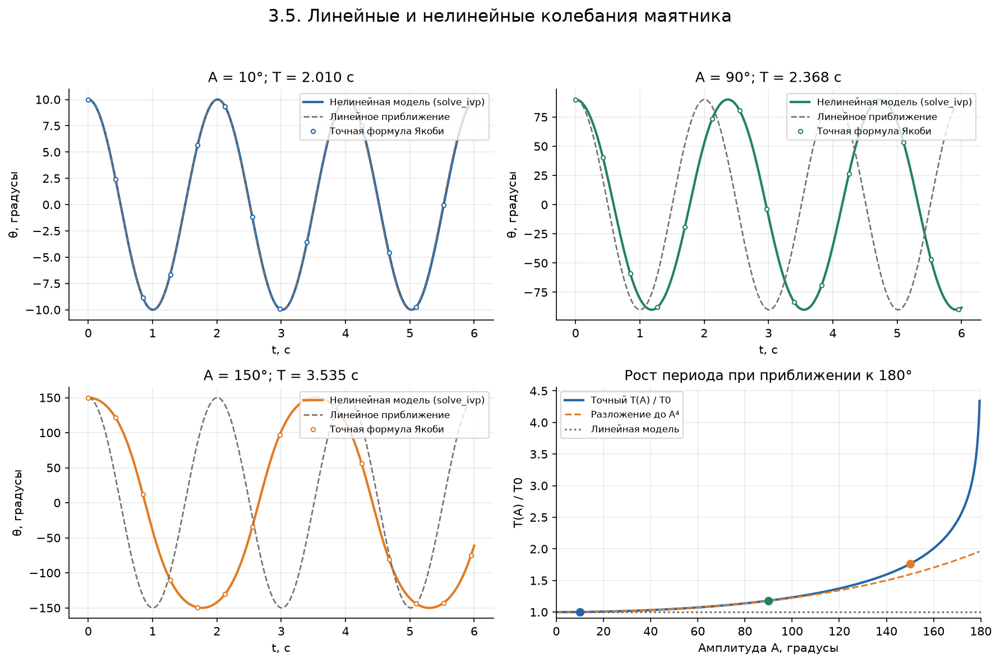

Сохранен рисунок: results/35_pendulum_time_period.png


In [23]:
# Угловые отклонения для трех амплитуд и зависимость периода от амплитуды.
pend_fig, pend_axes = plt.subplots(2, 2, figsize=(12, 8))
for pend_i, (pend_A_deg, pend_A, pend_solution, pend_color) in enumerate(zip(
        pend_amplitudes_deg, pend_amplitudes, pend_solutions, pend_colors)):
    pend_ax = pend_axes.flat[pend_i]
    pend_theta_num = pend_solution.sol(pend_time)[0]
    pend_theta_linear = pend_A * np.cos(pend_Omega * pend_time)
    pend_ax.plot(pend_time, np.rad2deg(pend_theta_num), color=pend_color,
                 lw=2, label='Нелинейная модель (solve_ivp)')
    pend_ax.plot(pend_time, np.rad2deg(pend_theta_linear), color='0.45',
                 ls='--', lw=1.3, label='Линейное приближение')
    pend_check_times = pend_time[::85]
    pend_check_theta, _ = pend_exact(pend_check_times, pend_A)
    pend_ax.plot(pend_check_times, np.rad2deg(pend_check_theta), 'o', ms=3.5,
                 mfc='white', mec=pend_color, label='Точная формула Якоби')
    pend_ax.set(title=f'A = {pend_A_deg:.0f}°; T = {pend_periods[pend_i]:.3f} с',
                 xlabel='t, с', ylabel='θ, градусы')
    pend_ax.legend(fontsize=8, loc='upper right')

pend_ax = pend_axes[1, 1]
pend_A_degrees_grid = np.linspace(0.0, 179.5, 600)
pend_A_radians_grid = np.deg2rad(pend_A_degrees_grid)
pend_period_ratio = (2.0 / np.pi) * ellipk(np.sin(pend_A_radians_grid / 2.0)**2)
pend_ax.plot(pend_A_degrees_grid, pend_period_ratio, color='#2667a6', lw=2,
             label='Точный T(A) / T0')
pend_ax.plot(pend_A_degrees_grid,
             1.0 + pend_A_radians_grid**2 / 16.0 + 11.0 * pend_A_radians_grid**4 / 3072.0,
             color='#e17c24', ls='--', label='Разложение до A⁴')
pend_ax.axhline(1.0, color='0.4', ls=':', label='Линейная модель')
for pend_A_deg, pend_T, pend_color in zip(pend_amplitudes_deg, pend_periods, pend_colors):
    pend_ax.scatter([pend_A_deg], [pend_T / pend_T0], color=pend_color, s=40, zorder=5)
pend_ax.set(xlim=(0, 180), ylim=(0.9, max(pend_period_ratio) * 1.05),
             title='Рост периода при приближении к 180°',
             xlabel='Амплитуда A, градусы', ylabel='T(A) / T0')
pend_ax.legend(fontsize=8, loc='upper left')
for pend_ax in pend_axes.flat:
    pend_ax.grid(True, alpha=0.25)
pend_fig.suptitle('3.5. Линейные и нелинейные колебания маятника', fontsize=15)
pend_fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(pend_fig, '35_pendulum_time_period')

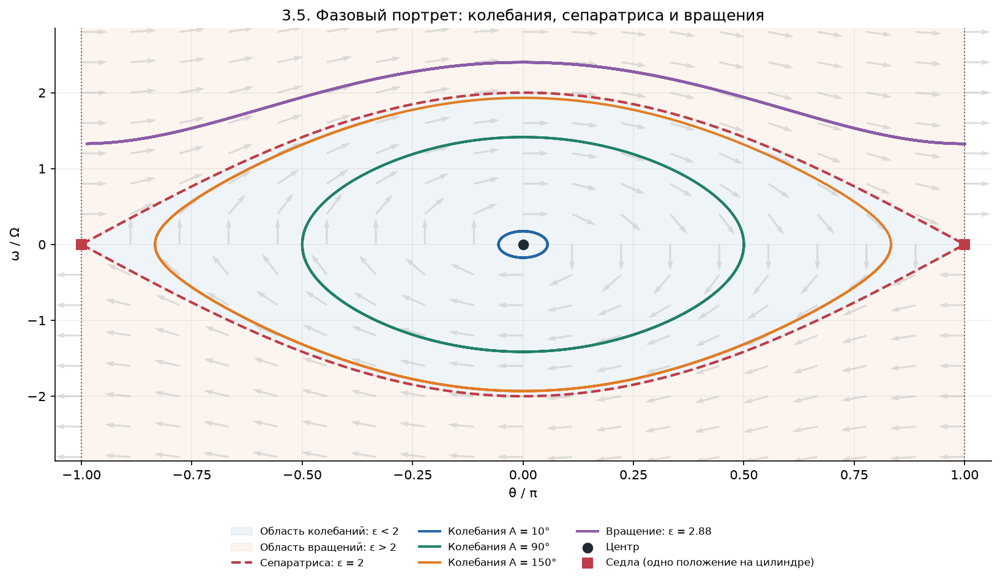

Сохранен рисунок: results/35_pendulum_phase.png


In [24]:
# Фазовый цилиндр, разрезанный по theta = ±pi.
pend_phase_fig, pend_phase_ax = plt.subplots(figsize=(11, 6.5))
pend_phase_theta = np.linspace(-np.pi, np.pi, 700)
pend_separatrix = 2.0 * np.cos(pend_phase_theta / 2.0)
pend_phase_ax.fill_between(pend_phase_theta / np.pi, -pend_separatrix,
                           pend_separatrix, color='#2667a6', alpha=0.07,
                           label='Область колебаний: ε < 2')
pend_phase_ax.fill_between(pend_phase_theta / np.pi, pend_separatrix, 3.0,
                           color='#e17c24', alpha=0.07, label='Область вращений: ε > 2')
pend_phase_ax.fill_between(pend_phase_theta / np.pi, -3.0, -pend_separatrix,
                           color='#e17c24', alpha=0.07)

# Направление фазового потока в координатах (theta/pi, omega/Omega).
pend_qtheta = np.linspace(-np.pi, np.pi, 19)
pend_qvel = np.linspace(-2.8, 2.8, 15)
pend_qT, pend_qV = np.meshgrid(pend_qtheta, pend_qvel)
pend_qU = pend_qV / np.pi
pend_qW = -np.sin(pend_qT)
pend_qN = np.hypot(pend_qU, pend_qW)
pend_qU = np.divide(pend_qU, pend_qN, out=np.zeros_like(pend_qU), where=pend_qN > 1e-12)
pend_qW = np.divide(pend_qW, pend_qN, out=np.zeros_like(pend_qW), where=pend_qN > 1e-12)
pend_phase_ax.quiver(pend_qT / np.pi, pend_qV, pend_qU, pend_qW,
                     color='0.78', alpha=0.6, angles='xy', scale=36, width=0.002, zorder=1)

for pend_sign in [-1, 1]:
    pend_phase_ax.plot(pend_phase_theta / np.pi, pend_sign * pend_separatrix,
                       color='#bd3d48', ls='--', lw=2,
                       label='Сепаратриса: ε = 2' if pend_sign == 1 else None)
for pend_A_deg, pend_solution, pend_color in zip(pend_amplitudes_deg, pend_solutions, pend_colors):
    pend_theta_plot, pend_omega_plot = pend_solution.sol(pend_time)
    pend_phase_ax.plot(pend_theta_plot / np.pi, pend_omega_plot / pend_Omega,
                       color=pend_color, lw=1.9, label=f'Колебания A = {pend_A_deg:.0f}°')
pend_phase_ax.plot(*pend_wrapped_trail(pend_rot_theta, pend_rot_omega),
                   color=pend_rotation_color, lw=2, label=f'Вращение: ε = {pend_rotation_epsilon:.2f}')
pend_phase_ax.scatter([0.0], [0.0], s=55, color='#202a35', zorder=6, label='Центр')
pend_phase_ax.scatter([-1.0, 1.0], [0.0, 0.0], s=65, marker='s', color='#bd3d48',
                      zorder=6, label='Седла (одно положение на цилиндре)')
pend_phase_ax.axvline(-1.0, color='0.4', ls=':', lw=1)
pend_phase_ax.axvline(1.0, color='0.4', ls=':', lw=1)
pend_phase_ax.set(xlim=(-1.06, 1.06), ylim=(-2.85, 2.85),
                   xlabel='θ / π', ylabel='ω / Ω',
                   title='3.5. Фазовый портрет: колебания, сепаратриса и вращения')
pend_phase_ax.grid(True, alpha=0.2)
pend_phase_ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13),
                      ncol=3, fontsize=8, frameon=False)
pend_phase_fig.tight_layout()
save_figure(pend_phase_fig, '35_pendulum_phase')

### 3.5.7. Синхронная анимация

На левой панели три независимых маятника с одинаковой длиной показаны с общей точкой подвеса для сравнения: малые колебания $A=10^\circ$, большие колебания $A=150^\circ$ и вращение с $\varepsilon>2$. Справа отображаются их положения и следы на фазовой плоскости. Границы $\theta/\pi=\pm1$ склеены в фазовый цилиндр; разрыв следа при переходе через границу является особенностью выбранной развертки угла, а не разрывом движения.

Все положения вычисляются из одного и того же численного решения `solve_ivp`, поэтому панели синхронизированы. Под рисунком обновляются физическое время, угол и безразмерная энергия. Время воспроизведения может отличаться от физического времени, указанного в кадре. Кнопки под анимацией позволяют остановить воспроизведение и выбрать отдельный кадр.

In [25]:
pend_anim_cases = [pend_solutions[0], pend_solutions[2], pend_rotation]
pend_anim_names = ['Малые колебания 10°', 'Большие колебания 150°', 'Вращение']
pend_anim_colors = [pend_colors[0], pend_colors[2], pend_rotation_color]
pend_anim_time = np.linspace(0.0, pend_duration, ANIM_FRAMES)
pend_anim_fig, (pend_ax_config, pend_ax_phase) = plt.subplots(
    1, 2, figsize=(11.7, 5.3), dpi=75
)
pend_anim_fig.subplots_adjust(left=0.075, right=0.98, bottom=0.32, top=0.83, wspace=0.30)
pend_anim_fig.suptitle('3.5. Маятник: движение и фазовая траектория', fontsize=12)

# Конфигурационное пространство: три модели с одинаковой точкой подвеса.
pend_circle_phi = np.linspace(0, 2 * np.pi, 180)
pend_ax_config.plot(pend_l * np.sin(pend_circle_phi), -pend_l * np.cos(pend_circle_phi),
                     color='0.85', ls=':', lw=1.2)
pend_ax_config.plot([0, 0], [-1.15 * pend_l, 1.15 * pend_l], color='0.85', lw=0.8)
pend_ax_config.scatter([0], [0], color='0.2', s=30, zorder=6)
pend_rods, pend_bobs = [], []
for pend_name, pend_color in zip(pend_anim_names, pend_anim_colors):
    pend_rod, = pend_ax_config.plot([], [], color=pend_color, lw=2.1, label=pend_name)
    pend_bob, = pend_ax_config.plot([], [], 'o', color=pend_color, ms=8, zorder=5)
    pend_rods.append(pend_rod)
    pend_bobs.append(pend_bob)
pend_ax_config.set(xlim=(-1.2 * pend_l, 1.2 * pend_l), ylim=(-1.2 * pend_l, 1.2 * pend_l),
                    xlabel='x, м', ylabel='y, м', title='Конфигурационное пространство')
pend_ax_config.set_aspect('equal', adjustable='box')
pend_anim_fig.legend(pend_rods, pend_anim_names, loc='upper center',
                       bbox_to_anchor=(0.5, 0.95), ncol=3, fontsize=8, frameon=False)

# Фазовая плоскость с критической энергией.
pend_ax_phase.fill_between(pend_phase_theta / np.pi, -pend_separatrix,
                           pend_separatrix, color='#2667a6', alpha=0.05)
pend_ax_phase.plot(pend_phase_theta / np.pi, pend_separatrix, '--', color='#bd3d48', lw=1.3)
pend_ax_phase.plot(pend_phase_theta / np.pi, -pend_separatrix, '--', color='#bd3d48', lw=1.3)
pend_ax_phase.scatter([0], [0], color='0.3', s=18, zorder=4)
pend_ax_phase.scatter([-1, 1], [0, 0], color='#bd3d48', marker='s', s=25, zorder=4)
pend_trails, pend_phase_dots = [], []
for pend_color in pend_anim_colors:
    pend_trail, = pend_ax_phase.plot([], [], color=pend_color, lw=1.4, alpha=0.65)
    pend_phase_dot, = pend_ax_phase.plot([], [], 'o', color=pend_color, ms=6, zorder=5)
    pend_trails.append(pend_trail)
    pend_phase_dots.append(pend_phase_dot)
pend_ax_phase.set(xlim=(-1.06, 1.06), ylim=(-2.65, 2.65),
                   xlabel='θ / π', ylabel='ω / Ω', title='Фазовая плоскость; красная линия: ε = 2')
for pend_ax in (pend_ax_config, pend_ax_phase):
    pend_ax.grid(True, alpha=0.22)
pend_clock = pend_anim_fig.text(0.075, 0.175, '', fontsize=10, weight='bold')
pend_status = [pend_anim_fig.text(0.075, 0.125 - i * 0.035, '', color=pend_anim_colors[i], fontsize=9)
               for i in range(len(pend_anim_cases))]


def pend_update(frame):
    t = pend_anim_time[frame]
    pend_clock.set_text(f't = {t:.2f} с; длина l = {pend_l:.2f} м; T0 = {pend_T0:.3f} с')
    history_time = pend_time[pend_time <= t]
    history_time = np.append(history_time, t)
    for i, solution in enumerate(pend_anim_cases):
        theta, omega = solution.sol(t)
        x, y = pend_l * np.sin(theta), -pend_l * np.cos(theta)
        pend_rods[i].set_data([0.0, x], [0.0, y])
        pend_bobs[i].set_data([x], [y])
        history_theta, history_omega = solution.sol(history_time)
        pend_trails[i].set_data(*pend_wrapped_trail(history_theta, history_omega))
        pend_phase_dots[i].set_data([float(pend_wrap(theta)) / np.pi], [omega / pend_Omega])
        epsilon = float(pend_energy(theta, omega))
        pend_status[i].set_text(
            f'{pend_anim_names[i]}: θ = {np.rad2deg(float(pend_wrap(theta))):7.2f}°; '
            f'ω = {omega:6.2f} рад/с; ε = {epsilon:.5f}'
        )
    return (*pend_rods, *pend_bobs, *pend_trails, *pend_phase_dots, pend_clock, *pend_status)


pend_animation = FuncAnimation(
    pend_anim_fig, pend_update, frames=ANIM_FRAMES,
    interval=1000 / ANIM_FPS, blit=False, repeat=False
)
display_animation(pend_animation)

Сохранен автономный плеер: results/animation_05.html


**Результат задачи 3.5.** Нелинейное уравнение маятника $\ddot\theta+(g/\ell)\sin\theta=0$ имеет точный первый интеграл энергии. Малые колебания близки к гармоническим, а при росте амплитуды период увеличивается по формуле $T=4\sqrt{\ell/g}\,K(\sin^2(A/2))$. Критическая энергия $E=2mg\ell$ задает сепаратрису: ниже нее происходят колебания, выше — вращения. Численное решение согласуется с точными функциями Якоби и сохраняет энергию в пределах заданной точности.

Статические результаты сохраняются в `results/35_pendulum_time_period.png` и `results/35_pendulum_phase.png`.

## Итоги и соответствие заданию

| Задача | Главный аналитический результат | Что проверено программно |
|---|---|---|
| 3.1 | $(x-x_v)^2=\frac{8g}{9c^2}(y_v-y)^3$ | Условие $v_y=-c$, ОДУ, совпадение $y(x)$ и $x(t),y(t)$, энергия |
| 3.2 | $x=F_a(x_0+v_{x0}t),\ y=F_b(y_0+v_{y0}t)$ | Границы, отражения, энергия, замыкание рациональной траектории |
| 3.3 | $y=a\cosh((x-x_c)/a)+C$, $a=H/(\lambda g)$ | Длина и опоры, баланс сил и моментов на элементе |
| 3.4 | $x=R(u+\sin u),\ y=R(1-\cos u)$, $T_*=\pi\sqrt{R/g}$ | Интеграл времени, численное прибытие, энергия |
| 3.5 | $\ddot\theta+(g/\ell)\sin\theta=0$, $T=4\sqrt{\ell/g}\,K(\sin^2(A/2))$ | Совпадение численного и точного решений, сохранение энергии |

Во всех разделах есть подробное аналитическое решение, код создания PNG и анимация
на `matplotlib.animation.FuncAnimation`. Все иллюстрации создаются кодом ноутбука,
внешние файлы с исходными данными не требуются.

### Источники и обозначения

1. **Постановки и требования:** приложенный файл «Практические занятия Листок 3 (3).pdf»:
   3.1 — с. 1–2; 3.2 — с. 2–4; 3.3 — с. 4–5; 3.4 — с. 5–6; 3.5 — с. 7–8.
   Составитель: П. Е. Рябов. Выводы формул приведены непосредственно в решении.
2. [Matplotlib: Animation.to_jshtml](https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.Animation.html#matplotlib.animation.Animation.to_jshtml) —
   вывод анимаций в автономный HTML-плеер.
3. [Matplotlib: widgets](https://matplotlib.org/stable/api/widgets_api.html) —
   дополнительный пример с кнопкой и ползунком.
4. [SciPy: solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) —
   численное решение уравнений движения и регистрация событий.
5. [SciPy: ellipk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.ellipk.html)
   и [ellipj](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.ellipj.html) —
   в API используется параметр $\mu=k^2$, а не модуль $k$.
6. [NIST DLMF, §22.19(i), The Pendulum](https://dlmf.nist.gov/22.19#i) —
   сверка формы точного решения для маятника. Обозначение модуля $k$ в DLMF
   переведено в параметр $\mu=k^2$, используемый в коде.

In [24]:
print('Созданные рисунки PNG:')
for path in SAVED_FIGURES:
    print(' ', path)
print('Созданные анимации HTML:')
for path in SAVED_ANIMATIONS:
    print(' ', path)
assert len(SAVED_ANIMATIONS) == 5
assert all(path.is_file() and path.stat().st_size > 0
           for path in SAVED_FIGURES + SAVED_ANIMATIONS)
print('Все пять задач выполнены; файлы графиков и плееров созданы.')

Созданные рисунки PNG:
  results/31_uniform_descent.png
  results/3_2_billiard.png
  results/3_2_billiard_torus.png
  results/3_3_catenary_shapes.png
  results/3_3_catenary_properties.png
  results/34_tautochrone.png
  results/35_pendulum_time_period.png
  results/35_pendulum_phase.png
Созданные анимации HTML:
  results/animation_01.html
  results/animation_02.html
  results/animation_03.html
  results/animation_04.html
  results/animation_05.html
Все пять задач выполнены; файлы графиков и плееров созданы.
